In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time

import generate_behavdf as gm

import plotly.graph_objects as go
from statsmodels.stats.anova import AnovaRM
import pingouin as pg
from modeller import circ_stats, fit_model, fit_vonmises

pd.set_option("display.max.columns", None)
pd.set_option("display.precision", 4)

msize = 10
axes_fontsize = 14
title_fontsize = 18
%load_ext autoreload
%autoreload 2

/opt/anaconda3/envs/mgs/lib/python3.10/site-packages/pandas/core/computation/expressions.py:21: UserWarning: Pandas requires version '2.8.4' or newer of 'numexpr' (version '2.8.3' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/opt/anaconda3/envs/mgs/lib/python3.10/site-packages/pandas/core/arrays/masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


Creating a new dataframe...
We have 23 subjects so far: [1, 2, 3, 5, 6, 7, 8, 9, 11, 12, 14, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 28]



In [2]:
df = gm.master_df
df.head()

,subjID,day,block,TMScond,stimPF,targOriCategory,targOriActual,stimSize,targX,targY,rho,polang,initDuration,sampleDuration,delay1Duration,delay2Duration,respDuration,feedbackDuration,itiDuration,trialDuration,initOri,finalOri,RT,errorOri,subjInitials,hemisphereStimulated,PT,oriSteps,initOffset,errOri_scaled,abserrorOri,stimPF_label,TMScond_label,TMSstatus,oriArray
0,1,1,1,3,1,150,150.4502,182,1264.895,691.8237,340.6045,26.4712,1.0002,0.2502,2.0002,2.0003,1.3968,1.0005,1.5002,9.1502,127.0883,141.0883,1.3240,9.3619,MRD1219,Left,42.0,52,-23.3619,-9.3619,9.3619,inPF,Middle TMS,TMS,"[127.08829584353, 127.08829584353, 127.0882958..."
1,1,1,1,3,1,150,141.0927,182,1264.895,691.8237,340.6045,26.4712,1.0003,0.2502,2.0002,2.0002,1.2362,1.0002,1.5003,8.9890,171.0400,135.0400,1.2067,6.0527,MRD1219,Left,42.0,49,29.9473,-6.0527,6.0527,inPF,Middle TMS,TMS,"[171.039968790904, 171.039968790904, 171.03996..."
2,1,1,1,3,0,30,39.4616,182,655.105,691.8237,340.6045,153.5288,1.0003,0.2502,2.0002,2.0002,1.1356,1.0002,2.5002,9.8879,80.2055,44.2055,1.1092,-4.7440,MRD1219,Left,42.0,45,40.7440,4.7440,4.7440,outPF,Middle TMS,TMS,"[80.2055161279619, 80.2055161279619, 80.205516..."
3,1,1,1,3,1,30,24.5225,182,1264.895,691.8237,340.6045,26.4712,1.0002,0.2502,2.0003,2.0003,1.1849,1.0002,1.5002,8.9374,21.4196,22.4196,1.1534,2.1029,MRD1219,Left,42.0,47,-3.1029,-2.1029,2.1029,inPF,Middle TMS,TMS,"[21.4195826805078, 21.4195826805078, 21.419582..."
4,1,1,1,3,0,150,146.0840,182,655.105,691.8237,340.6045,153.5288,1.0006,0.2505,2.0007,2.0008,1.7367,1.0006,2.5006,10.4944,91.0723,142.0723,1.7104,4.0117,MRD1219,Left,42.0,69,-55.0117,-4.0117,4.0117,outPF,Middle TMS,TMS,"[91.0722692997256, 91.0722692997256, 91.072269..."


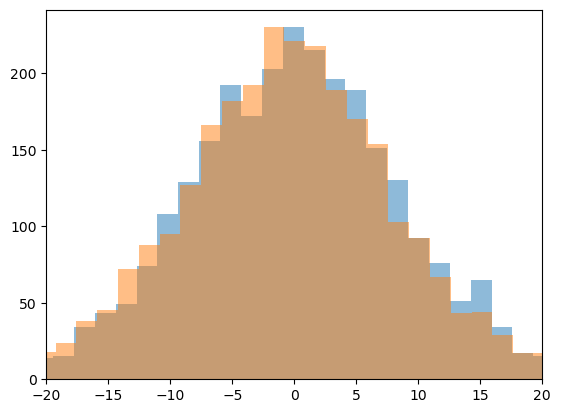

In [16]:
plt.figure()
plt.hist(df[(df['TMScond']==2) & (df['stimPF_label'] == 'inPF')]['errOri_scaled'], bins=100, alpha =0.5)
plt.hist(df[(df['TMScond']==2) & (df['stimPF_label'] == 'outPF')]['errOri_scaled'], bins=100, alpha=0.5)

# plt.hist(df[df['TMScond']==2]['errOri_scaled'], bins=100)
# plt.hist(df[df['TMScond']==3]['errOri_scaled'], bins=100)
plt.xlim([-20, 20])
plt.show()

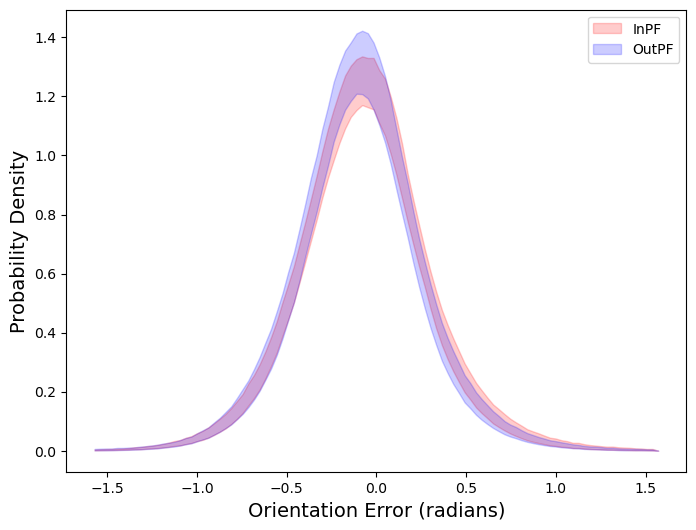

In [3]:
oriX = np.linspace(-np.pi/2, np.pi/2, 100)
oriBinCounterIn = np.zeros((len(df['subjID'].unique()), len(oriX)))
oriBinCounterOut = np.zeros((len(df['subjID'].unique()), len(oriX)))

vonMisFitIn = np.zeros((len(df['subjID'].unique()), len(oriX)))
vonMisFitOut = np.zeros((len(df['subjID'].unique()), len(oriX)))

for i, sidx in enumerate(df['subjID'].unique()):
    sbDfIn = df[(df['subjID'] == sidx) & (df['TMScond_label'] == 'Middle TMS') 
                & (df['stimPF_label'] == 'inPF') & (df['targOriCategory'] == 150)]
    sbDfOut = df[(df['subjID'] == sidx) & (df['TMScond_label'] == 'Middle TMS')
                 & (df['stimPF_label'] == 'outPF') & (df['targOriCategory'] == 150)]
    thErrorIn = np.deg2rad(sbDfIn['errOri_scaled'].values) * 2
    thErrorOut = np.deg2rad(sbDfOut['errOri_scaled'].values) * 2
    oriBinCounterIn[i, :-1] = np.histogram(thErrorIn, bins=oriX, density=True)[0]
    oriBinCounterOut[i, :-1] = np.histogram(thErrorOut, bins=oriX, density=True)[0]
    meanThisIn, stdThisIn, varThisIn = circ_stats(thErrorIn)
    meanThisOut, stdThisOut, varThisOut = circ_stats(thErrorOut)
    muIn, kappaIn = fit_vonmises(thErrorIn)
    muOut, kappaOut = fit_vonmises(thErrorOut)
    vonMisSampleIn = np.random.vonmises(muIn, kappaIn, size=100000)
    vonMisSampleOut = np.random.vonmises(muOut, kappaOut, size=100000)
    vonMisFitIn[i, :-1] = np.histogram(vonMisSampleIn, bins=oriX, density=True)[0]
    vonMisFitOut[i, :-1] = np.histogram(vonMisSampleOut, bins=oriX, density=True)[0]


mean_actualIn = np.mean(oriBinCounterIn, axis=0)
sem_actualIn = np.std(oriBinCounterIn, axis=0) / np.sqrt(oriBinCounterIn.shape[0])

mean_actualOut = np.mean(oriBinCounterOut, axis=0)
sem_actualOut = np.std(oriBinCounterOut, axis=0) / np.sqrt(oriBinCounterOut.shape[0])

mean_fitIn = np.mean(vonMisFitIn, axis=0)
sem_fitIn = np.std(vonMisFitIn, axis=0) / np.sqrt(vonMisFitIn.shape[0])

mean_fitOut = np.mean(vonMisFitOut, axis=0)
sem_fitOut = np.std(vonMisFitOut, axis=0) / np.sqrt(vonMisFitOut.shape[0])

plt.figure(figsize=(8, 6))
# plt.errorbar(oriX, mean_actualIn, yerr=sem_actualIn, fmt='o', color='red', label='InPF')
plt.fill_between(oriX, mean_fitIn - sem_fitIn, mean_fitIn + sem_fitIn, color='red', alpha=0.2, label='InPF')
# plt.errorbar(oriX, mean_actualOut, yerr=sem_actualOut, fmt='o', color='blue', label='outPF')
plt.fill_between(oriX, mean_fitOut - sem_fitOut, mean_fitOut + sem_fitOut, color='blue', alpha=0.2, label='OutPF')
# plt.plot(oriX, oriBinCounter[0, :])
# plt.plot(oriX, vonMisFit[0, :])
plt.legend()
plt.xlabel('Orientation Error (radians)', fontsize=axes_fontsize)
plt.ylabel('Probability Density', fontsize=axes_fontsize)
plt.show()

In [108]:
df['TMScond_label'].unique()

array(['Middle TMS', 'Early TMS', 'No TMS'], dtype=object)

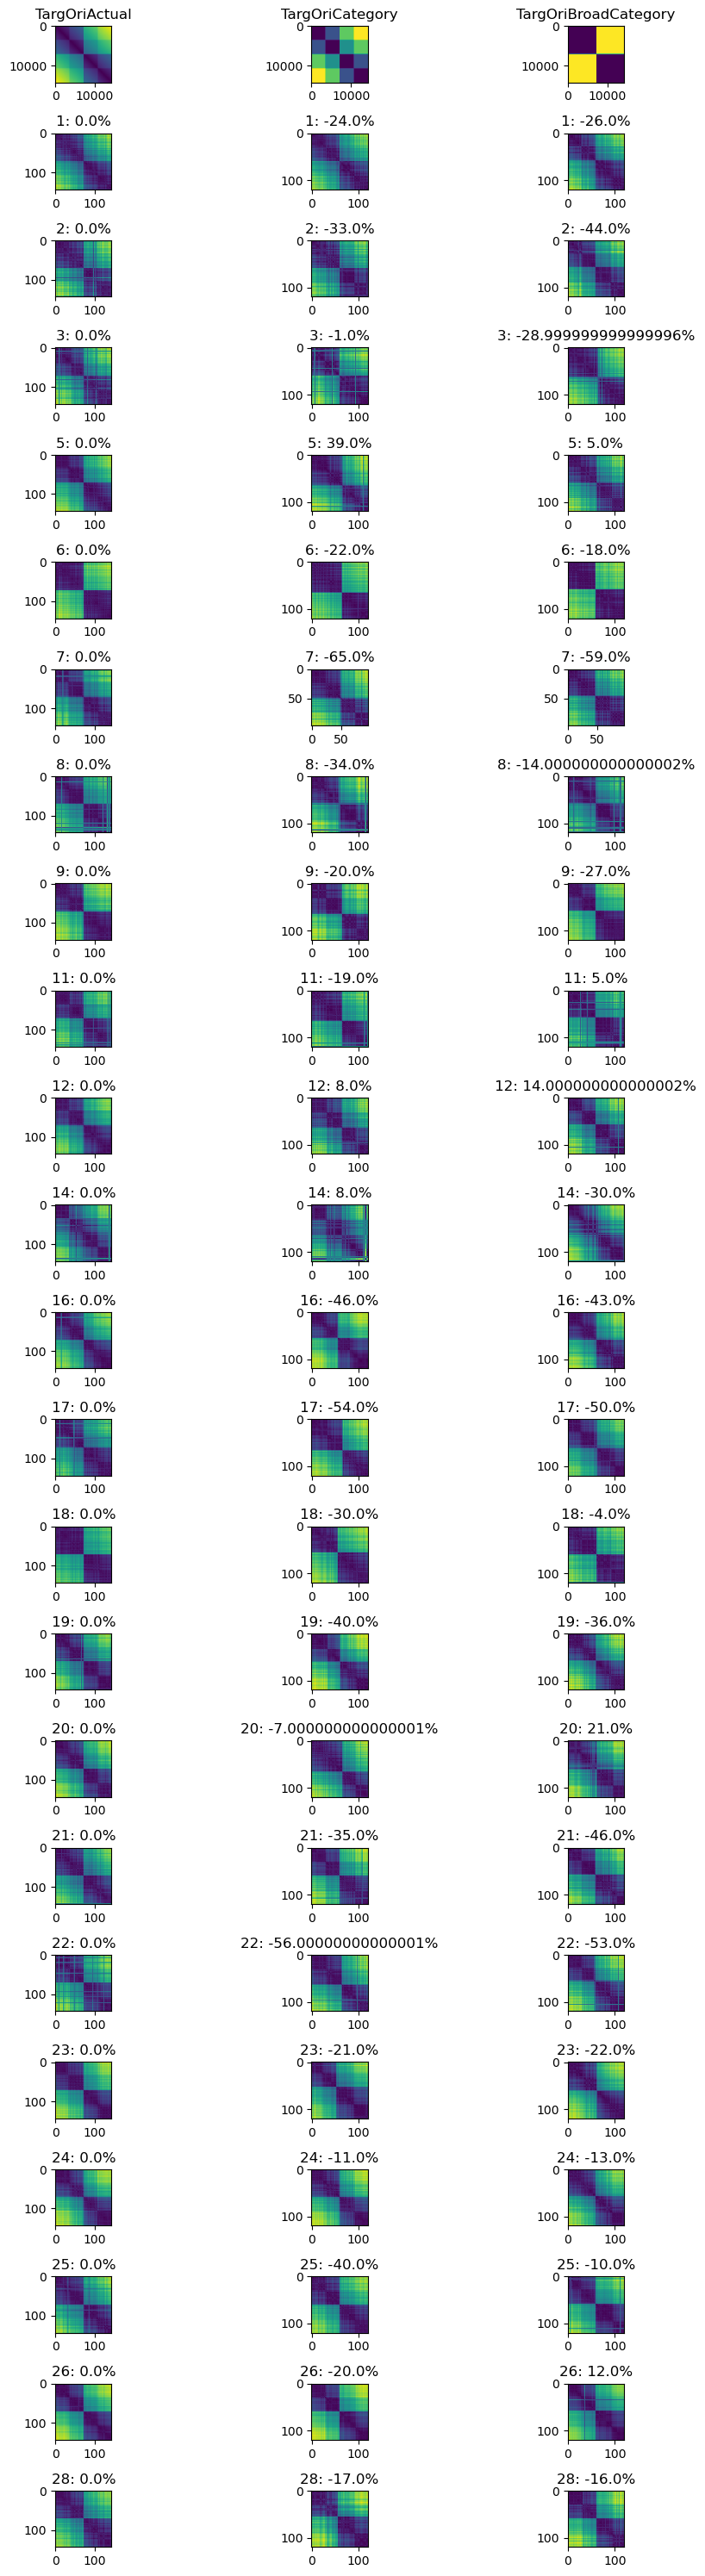

In [126]:
x = df['targOriActual'].values
x_idx = np.argsort(x)
x_sort = x[x_idx]

x_cat = df['targOriCategory'].values
x_cat_sort = x_cat[x_idx]

x_cat_broad = np.array([45 if i < 90 else 135 for i in x_cat_sort])

# Create a matrix of all possible pairwise differences
diffs_x = np.sqrt((x_sort[:, None] - x_sort[None, :]) ** 2)
diffs_xcat = np.sqrt((x_cat_sort[:, None] - x_cat_sort[None, :]) ** 2)
diffs_xBroadCat = np.sqrt((x_cat_broad[:, None] - x_cat_broad[None, :]) ** 2)

f, axs = plt.subplots(len(df['subjID'].unique())+1, 3, figsize=(10, 30))
# axs = axs.flatten()

axs[0, 0].imshow(diffs_x, cmap='viridis')
axs[0, 0].set_title('TargOriActual')
axs[0, 1].imshow(diffs_xcat, cmap='viridis')
axs[0, 1].set_title('TargOriCategory')
axs[0, 2].imshow(diffs_xBroadCat, cmap='viridis')
axs[0, 2].set_title('TargOriBroadCategory')


tmsconds = ['No TMS', 'Early TMS', 'Middle TMS']
for i, sidx in enumerate(df['subjID'].unique()):
    nt_diff = 0
    for j, cond in enumerate(tmsconds):
        if j == 0:
            df_a = df[(df['subjID'] == sidx)  &
                      (df['TMScond_label'] == cond)]
        else:
            df_a = df[(df['subjID'] == sidx) &
                    (df['stimPF'] == 1) &
                    (df['TMScond_label'] == cond)]

        x = df_a['targOriActual'].values
        x_idx = np.argsort(x)
        x_sort = x[x_idx]

        x_cat = df_a['targOriCategory'].values
        x_cat_sort = x_cat[x_idx]

        x_cat_broad = np.array([45 if i < 90 else 135 for i in x_cat_sort])

        # Create a matrix of all possible pairwise differences
        diffs_x = np.sqrt((x_sort[:, None] - x_sort[None, :]) ** 2)
        diffs_xcat = np.sqrt((x_cat_sort[:, None] - x_cat_sort[None, :]) ** 2)
        diffs_xBroadCat = np.sqrt((x_sort[:, None] - x_cat_broad[None, :]) ** 2)


        y = df_a['finalOri'].values
        y_sort = y[x_idx]
        diffs_y = np.sqrt((y_sort[:, None] - y_sort[None, :]) ** 2)

        axs[1+i, j].imshow(diffs_y, cmap='viridis')
        
        # Compute difference between diff_y and diff_x and diff_xcat
        distance_fromCat = np.linalg.norm(diffs_y - diffs_xcat, ord='fro')
        distance_fromOri = np.linalg.norm(diffs_y - diffs_x, ord='fro')
        distance_fromBroadCat = np.linalg.norm(diffs_y - diffs_xBroadCat, ord='fro')

        if j == 0:
            nt_diff = distance_fromOri
        
        relRatio = round(distance_fromOri / nt_diff - 1, 2) * 100
            

        # Choose the smaller distance
        min_distance = np.min([distance_fromCat, distance_fromOri, distance_fromBroadCat])
        # if min_distance == distance_fromCat:
        #     axs[1+i, j].set_title(f'{sidx}: TargOriCategory')
        # elif min_distance == distance_fromOri:
        #     axs[1+i, j].set_title(f'{sidx}: TargOriActual')
        # else:
        #     axs[1+i, j].set_title(f'{sidx}: TargOriBroadCategory')
        axs[1+i, j].set_title(f'{sidx}: {relRatio}%')

plt.tight_layout()
plt.show()

In [86]:
diffs_x.min(), diffs_x.max(), diffs_y.min(), diffs_y.max()

(0.0, 139.9353807757138, 0.0, 179.86195207496118)

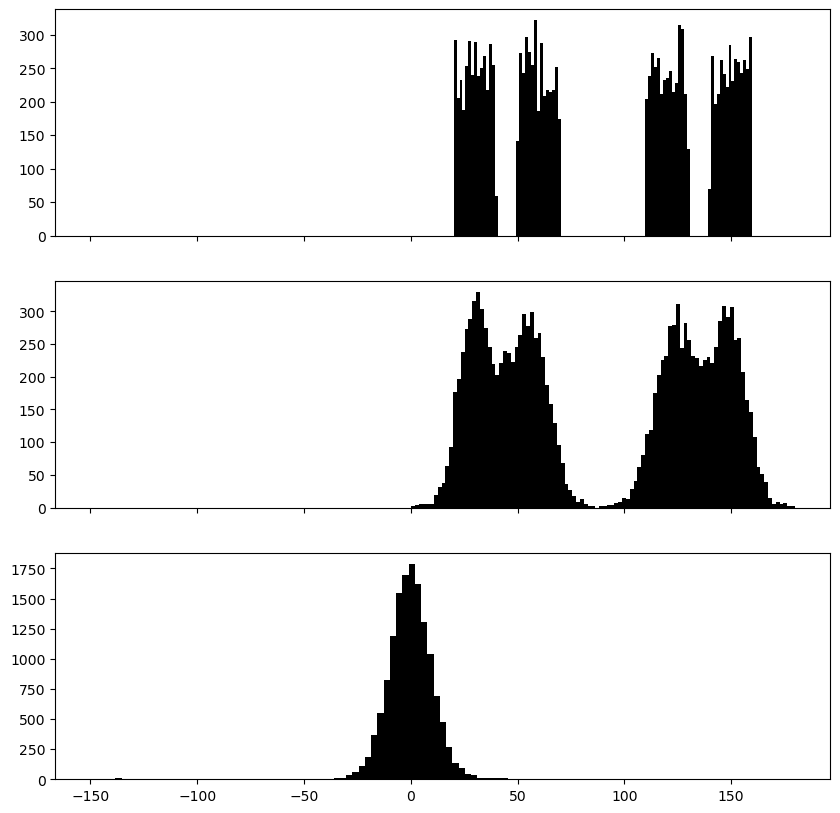

In [76]:
f, axs = plt.subplots(3, 1, figsize=(10, 10), sharex=True)
df_a = df.copy() #[df["targOriCategory"] == 120]
df_a["finalOri"] = df_a["finalOri"] % 180 
# df_a["finalOri"] -= 90
axs[0].hist(df_a["targOriActual"], bins=100, color="black")

axs[1].hist(df_a["finalOri"], bins=100, color="black")

errTemp = df_a["finalOri"] - df_a["targOriCategory"]
axs[2].hist(errTemp, bins=100, color="black")

plt.show()


In [77]:
errTemp.min(), errTemp.max()

(-149.94621803613018, 142.118461998263)

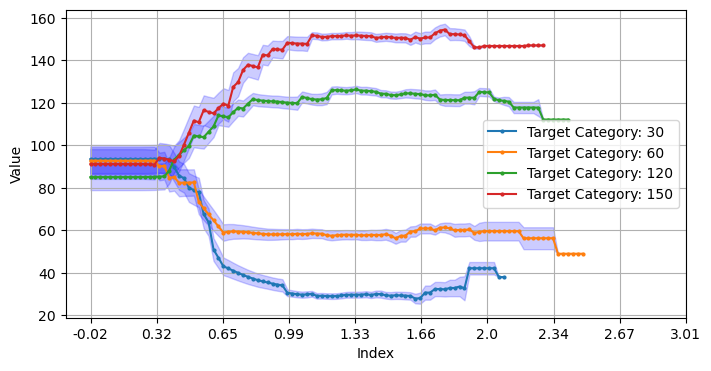

In [106]:
df_a = df[(df['subjID'] == 1)]# & (df['targOriCategory'] == 30)]

df_t = df[(df['subjID'] != 2)] # Remove subject 2 here cuz timings on day2 are off (no clue why?)
oriSamps = np.array([len(arr) for arr in df_t['oriArray']])

y = df_t['RT']
x = oriSamps
# perform linear regression
tempSlope, tempIntercept = np.polyfit(x, y, 1)
xticks = np.linspace(0, max(x), 10)
xticks_update = [round(tempSlope*tick + tempIntercept, 2) for tick in xticks]

tarCat = df_a['targOriCategory'].unique()
tarCat = np.sort(tarCat)
plt.figure(figsize=(8, 4))
for i, cat in enumerate(tarCat):
    df_b = df_a[(df_a['targOriCategory'] == cat) & (df_a['TMSstatus']=='TMS') & (df_a['stimPF']==1)]
    
    max_length = max(len(arr) for arr in df_b['oriArray'])
    padded_arrays = np.array([np.pad(arr, (0, max_length - len(arr)), constant_values=np.nan) for arr in df_b['oriArray']])

    # Compute the mean while ignoring NaN values
    mean_sequence = np.nanmean(padded_arrays, axis=0)
    sem_sequence = np.nanstd(padded_arrays, axis=0) / np.sqrt(np.sum(~np.isnan(padded_arrays), axis=0))


    # Plot the averaged sequence
    
    plt.plot(mean_sequence, marker='o', label=f'Target Category: {cat}', markersize=2)
    plt.fill_between(
        range(len(mean_sequence)), 
        mean_sequence - sem_sequence, 
        mean_sequence + sem_sequence, 
        color='blue', 
        alpha=0.2, 
    )
    # plt.plot(padded_arrays, marker='o', label=f'Target Category: {cat}', markersize=2)
    plt.xlabel('Index')
    plt.ylabel('Value')
    plt.xticks(xticks, xticks_update)
    plt.legend()
    plt.grid(True)
    # plt.show()
plt.show()

In [20]:
df['polang'].min(), df['polang'].max()

(6.87089767980003, 173.1291023202)

In [19]:
errTemp.min(), errTemp.max()

(-85.172546442255, 41.667286708267994)

### Learning trends

Subject 1 has 12 trials with abserrorOri > 3 std devs from the mean
Subject 2 has 5 trials with abserrorOri > 3 std devs from the mean
Subject 3 has 11 trials with abserrorOri > 3 std devs from the mean
Subject 5 has 8 trials with abserrorOri > 3 std devs from the mean
Subject 6 has 4 trials with abserrorOri > 3 std devs from the mean
Subject 7 has 6 trials with abserrorOri > 3 std devs from the mean
Subject 8 has 17 trials with abserrorOri > 3 std devs from the mean
Subject 9 has 5 trials with abserrorOri > 3 std devs from the mean
Subject 11 has 7 trials with abserrorOri > 3 std devs from the mean
Subject 12 has 4 trials with abserrorOri > 3 std devs from the mean
Subject 14 has 18 trials with abserrorOri > 3 std devs from the mean
Subject 16 has 7 trials with abserrorOri > 3 std devs from the mean
Subject 17 has 9 trials with abserrorOri > 3 std devs from the mean
Subject 18 has 4 trials with abserrorOri > 3 std devs from the mean
Subject 19 has 7 trials with abserrorOri > 3 std dev

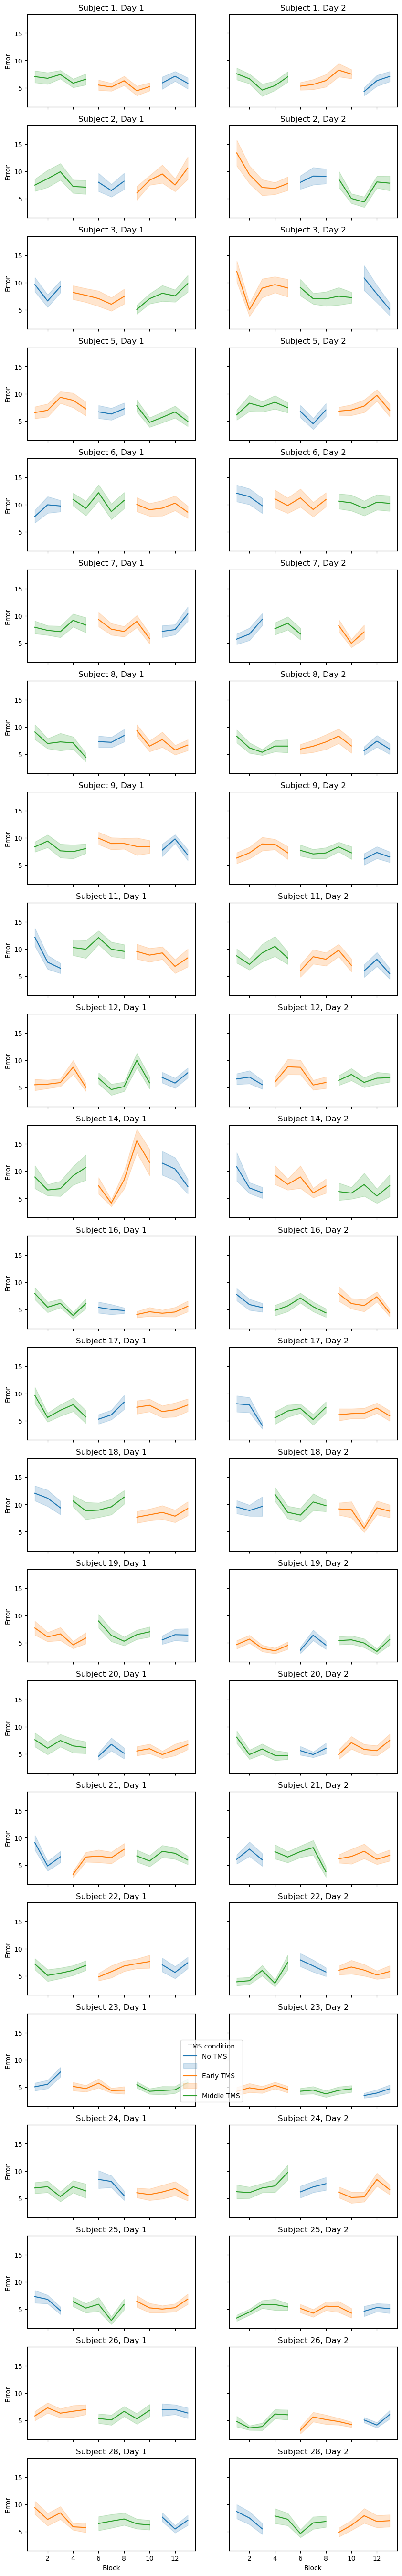

In [107]:
unique_subs = df['subjID'].unique()
f, axs = plt.subplots(len(unique_subs), 2, figsize=(10, 3*len(unique_subs)), sharex=True, sharey=True)

metric_to_plot = 'abserrorOri'
# metric_to_plot = 'RT'
for i, sub in enumerate(unique_subs):
    subdf = df[df['subjID'] == sub]
    # Eliminate rows where abserrorOri is greater than 3 std devs from the mean
    elimTrials = np.abs(subdf['abserrorOri'] - subdf['abserrorOri'].mean()) > 3*subdf['abserrorOri'].std()
    print(f'Subject {sub} has {elimTrials.sum()} trials with abserrorOri > 3 std devs from the mean')
    subdf = subdf[~elimTrials]

    # Plot distributions for RT and error
    nunique_days = subdf['day'].nunique()


    if nunique_days == 1:
        sns.lineplot(x='block', y=metric_to_plot, hue='TMScond_label', data=subdf, ax=axs[i, 0], errorbar='se', legend=False, hue_order=['No TMS', 'Early TMS', 'Middle TMS'])
        axs[i, 0].set_title(f'Subject {sub}, Day 1')
        axs[i, 0].set_xlabel('Block')
        if metric_to_plot == 'abserrorOri':
            axs[i, 0].set_ylabel('Error')
        else:
            axs[i, 0].set_ylabel('RT')
        # axs[i, 0].legend(title='Stimulus position')
    else:
        
        sns.lineplot(x='block', y=metric_to_plot, hue='TMScond_label', data=subdf[subdf['day']==1], ax=axs[i, 0], errorbar='se', legend=False, hue_order=['No TMS', 'Early TMS', 'Middle TMS'])
        axs[i, 0].set_title(f'Subject {sub}, Day 1')
        axs[i, 0].set_xlabel('Block')
        if metric_to_plot == 'abserrorOri':
            axs[i, 0].set_ylabel('Error')
        else:
            axs[i, 0].set_ylabel('RT')
        # axs[i, 0].legend(title='Stimulus position')

        sns.lineplot(x='block', y=metric_to_plot, hue='TMScond_label', data=subdf[subdf['day']==2], ax=axs[i, 1], errorbar='se', legend=False, hue_order=['No TMS', 'Early TMS', 'Middle TMS'])
        axs[i, 1].set_title(f'Subject {sub}, Day 2')
        axs[i, 1].set_xlabel('Block')
        if metric_to_plot == 'abserrorOri':
            axs[i, 1].set_ylabel('Error')
        else:
            axs[i, 1].set_ylabel('RT')
# plt.legend(title='TMS condition', loc='upper right')
plt.legend(title='TMS condition', loc='upper right', bbox_to_anchor=(0.1, 5.55), labels=['No TMS', None, 'Early TMS', '', 'Middle TMS'])
# plt.tight_layout()
plt.show()

In [ ]:
exploratory_cols = ['TMScond', 'stimPF', 'targOriCategory', 'targOriActual', 'respDuration', 'initOri', 'initOffset', 'finalOri', 'RT', 'errorOri', 'errOri_scaled', 'abserrorOri', 'oriSteps']
plt.figure(figsize=(15, 10))
sns.heatmap(df[exploratory_cols].corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix', fontsize=title_fontsize)
plt.show()

In [ ]:
# Explore raw reports and biases
nrows = 4
ncols = df['subjID'].nunique() // nrows + 1
f, axs = plt.subplots(nrows, ncols, figsize=(5*ncols, 5*nrows), sharex=True, sharey=True)
for i, s in enumerate(df['subjID'].unique()):
    subdf = df[df['subjID']==s]
    sns.scatterplot(x='targOriActual', y='finalOri', data=subdf, ax=axs[i//ncols, i%ncols])
    axs[i//ncols, i%ncols].plot([0, 180], [0, 180], 'k--')
    axs[i//ncols, i%ncols].set_xlim([0, 180])
    axs[i//ncols, i%ncols].set_ylim([0, 180])
    axs[i//ncols, i%ncols].set_title(f'Subject {s}')
    axs[i//ncols, i%ncols].set_xlabel('Target Orientation')
    axs[i//ncols, i%ncols].set_ylabel('Final Orientation')
plt.tight_layout()
plt.show()

# Observations:
# All participants exhibit a strong tendency to report the target orientation
# subjects 3, 6, 11, 14, 17, 18, 22 show a bias towards 45 and 135 degrees
# We can also see some subjects have few trials that are extremey off from the target orientation, probably they did not look at the target or were lost in their imagination

In [ ]:
plt.figure(figsize=(15, 10))
sns.pairplot(df[exploratory_cols])
plt.show()

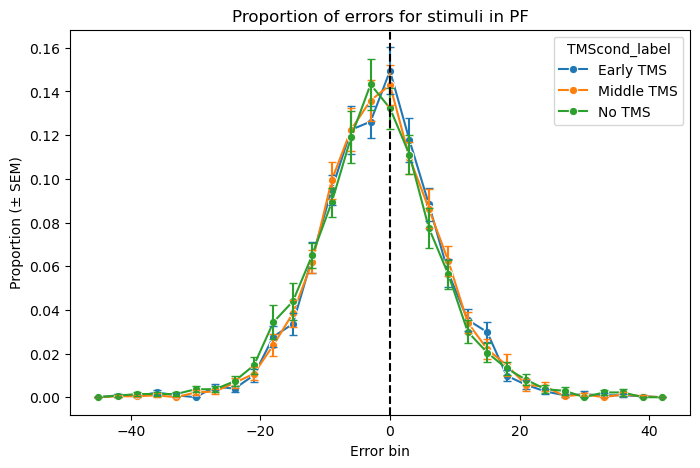

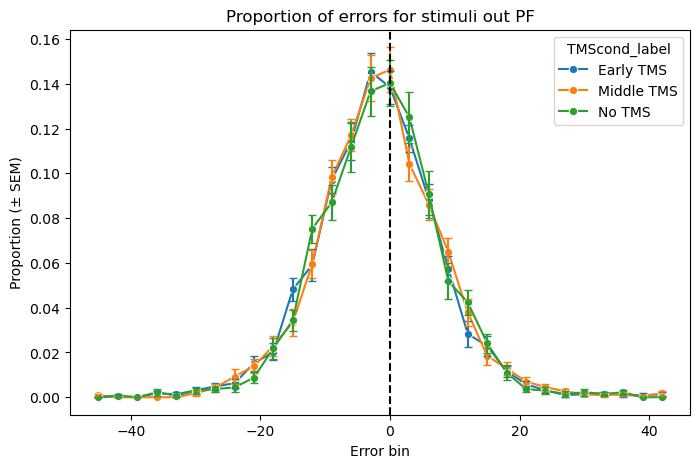

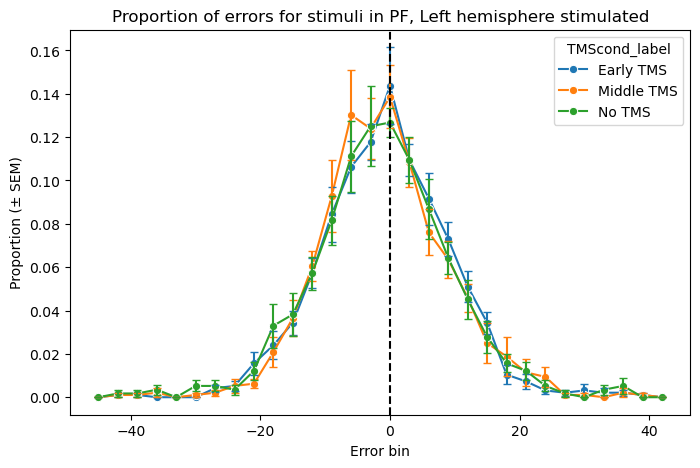

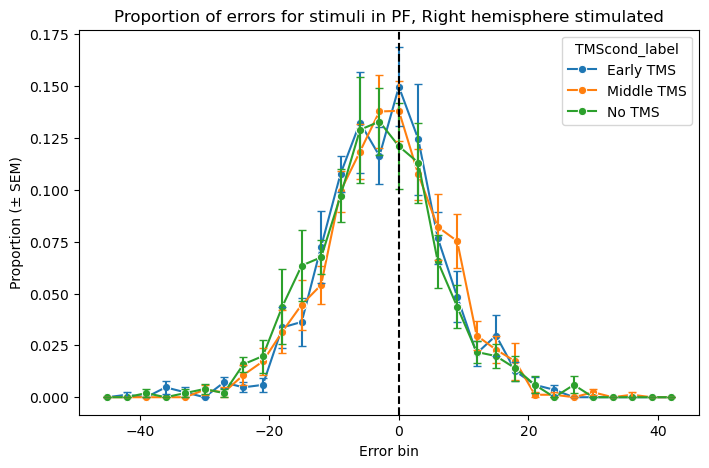

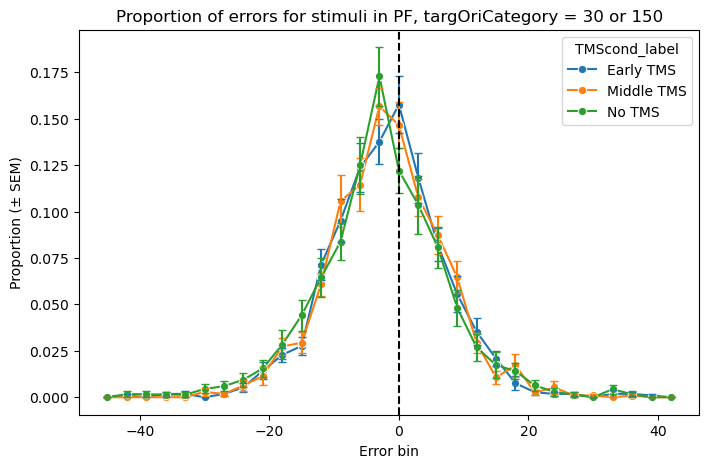

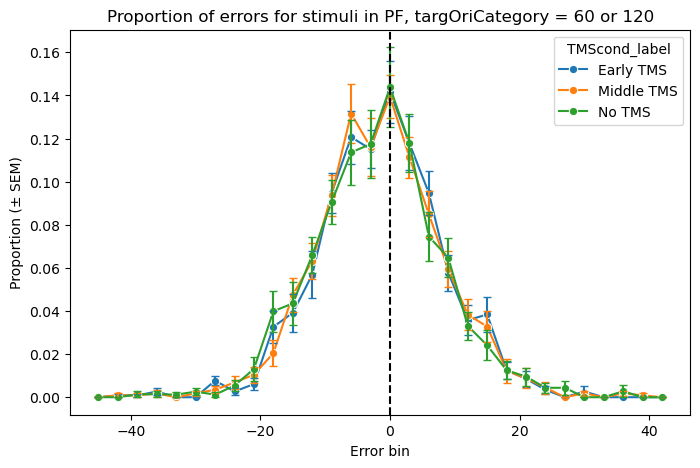

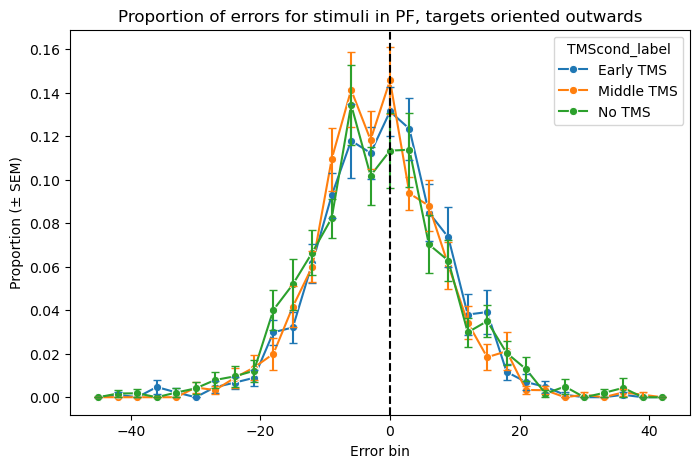

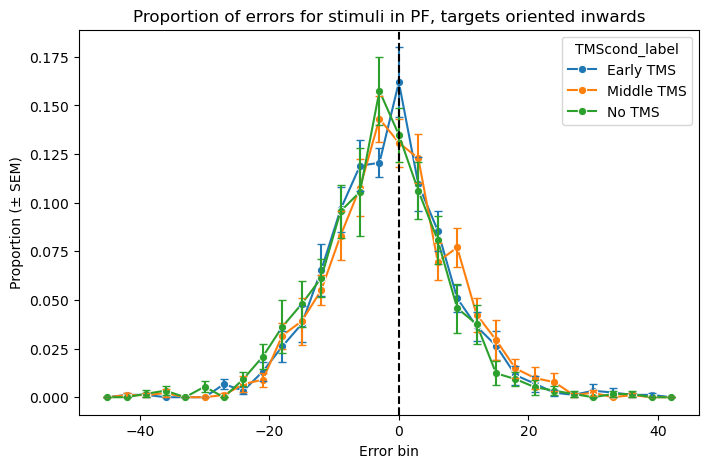

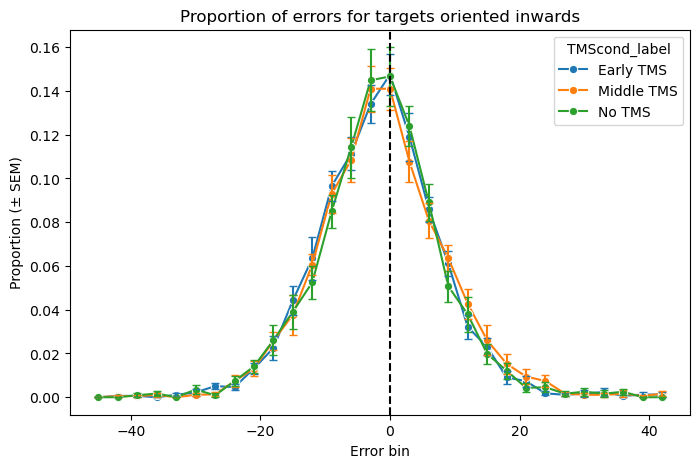

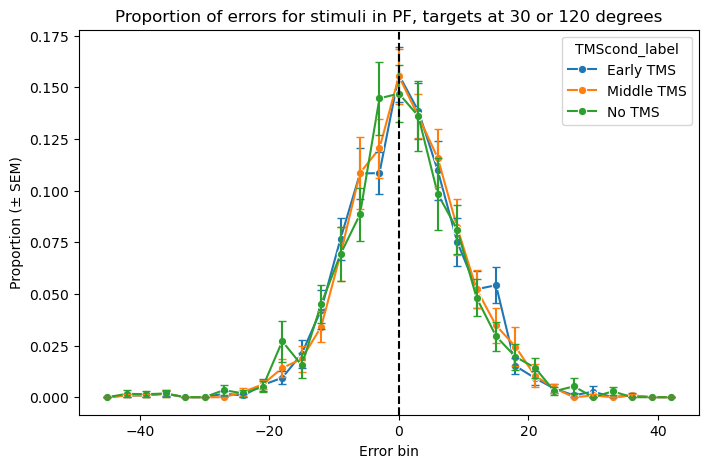

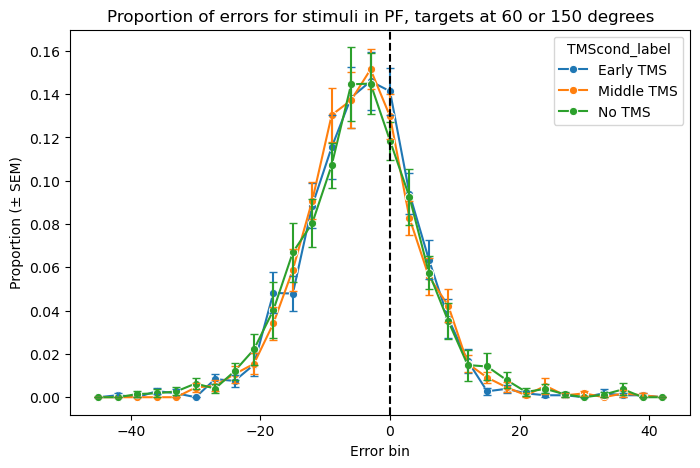

In [ ]:
def get_binned_errors(df, metric_to_plot, eval_bins):
    '''
    Function to bin the errors into equal bins to compute histograms
    '''
    error_binned = pd.cut(df[metric_to_plot], eval_bins, labels=eval_bins[:-1])
    return error_binned

def plot_bins(bin_counts, total_counts, title):
    bin_counts = pd.merge(bin_counts, total_counts, on=['subjID', 'TMScond_label'])
    bin_counts['proportion'] = bin_counts['bin_count'] / bin_counts['total_trials']

    final_grouped = bin_counts.groupby(['errorOri_bin', 'TMScond_label'], observed=False).agg(
        mean_proportion=('proportion', 'mean'),
        sem_proportion=('proportion', 'sem')).reset_index()

    plt.figure(figsize=(8, 5))
    sns.lineplot(
        x='errorOri_bin', 
        y='mean_proportion', 
        hue='TMScond_label', 
        data=final_grouped, 
        marker='o', 
        err_style='bars', 
        errorbar=None)
    for cond_label in final_grouped['TMScond_label'].unique():
        cond_data = final_grouped[final_grouped['TMScond_label'] == cond_label]
        plt.errorbar(
            cond_data['errorOri_bin'].astype(float), 
            cond_data['mean_proportion'], 
            yerr=cond_data['sem_proportion'], 
            fmt='none', 
            capsize=3, 
            color=sns.color_palette()[list(final_grouped['TMScond_label'].unique()).index(cond_label)]
        )
    plt.axvline(0, color='black', linestyle='--')
    plt.xlabel('Error bin')
    plt.ylabel('Proportion (± SEM)')
    plt.title(title)
    plt.show()

n_bins = 30
eval_bins = np.linspace(-45, 45, n_bins+1)
df_temp = df.copy()
df_temp['errorOri_bin'] = get_binned_errors(df_temp, 'errOri_scaled', eval_bins)

# Plot for stimulus in PF
total_counts = df_temp[df_temp['stimPF'] == 1].groupby(['subjID', 'TMScond_label'], observed=False).size().reset_index(name='total_trials')
bin_counts = df_temp[df_temp['stimPF'] == 1].groupby(['errorOri_bin', 'subjID', 'TMScond_label'], observed=False).size().reset_index(name='bin_count')
plot_bins(bin_counts, total_counts, 'Proportion of errors for stimuli in PF')

# Plot for stimulus out PF
total_counts = df_temp[df_temp['stimPF'] == 0].groupby(['subjID', 'TMScond_label'], observed=False).size().reset_index(name='total_trials')
bin_counts = df_temp[df_temp['stimPF'] == 0].groupby(['errorOri_bin', 'subjID', 'TMScond_label'], observed=False).size().reset_index(name='bin_count')
plot_bins(bin_counts, total_counts, 'Proportion of errors for stimuli out PF')

# Plot for when stimPF == 1, if hemisphere is Left
total_counts = df_temp[(df_temp['stimPF'] == 1) & (df_temp['hemisphereStimulated'] == 'Left')].groupby(['subjID', 'TMScond_label'], observed=False).size().reset_index(name='total_trials')
bin_counts = df_temp[(df_temp['stimPF'] == 1) & (df_temp['hemisphereStimulated'] == 'Left')].groupby(['errorOri_bin', 'subjID', 'TMScond_label'], observed=False).size().reset_index(name='bin_count')
plot_bins(bin_counts, total_counts, 'Proportion of errors for stimuli in PF, Left hemisphere stimulated')

# Plot for when stimPF == 1, if hemisphere is Right
total_counts = df_temp[(df_temp['stimPF'] == 1) & (df_temp['hemisphereStimulated'] == 'Right')].groupby(['subjID', 'TMScond_label'], observed=False).size().reset_index(name='total_trials')
bin_counts = df_temp[(df_temp['stimPF'] == 1) & (df_temp['hemisphereStimulated'] == 'Right')].groupby(['errorOri_bin', 'subjID', 'TMScond_label'], observed=False).size().reset_index(name='bin_count')
plot_bins(bin_counts, total_counts, 'Proportion of errors for stimuli in PF, Right hemisphere stimulated')

# Plot for when stimPF == 1, targOriCategory = 30 or 150
total_counts = df_temp[(df_temp['stimPF'] == 1) & (df_temp['targOriCategory'].isin([30, 150]))].groupby(['subjID', 'TMScond_label'], observed=False).size().reset_index(name='total_trials')
bin_counts = df_temp[(df_temp['stimPF'] == 1) & (df_temp['targOriCategory'].isin([30, 150]))].groupby(['errorOri_bin', 'subjID', 'TMScond_label'], observed=False).size().reset_index(name='bin_count')
plot_bins(bin_counts, total_counts, 'Proportion of errors for stimuli in PF, targOriCategory = 30 or 150')

# Plot for when stimPF == 1, targOriCategory = 60 or 120
total_counts = df_temp[(df_temp['stimPF'] == 1) & (df_temp['targOriCategory'].isin([60, 120]))].groupby(['subjID', 'TMScond_label'], observed=False).size().reset_index(name='total_trials')
bin_counts = df_temp[(df_temp['stimPF'] == 1) & (df_temp['targOriCategory'].isin([60, 120]))].groupby(['errorOri_bin', 'subjID', 'TMScond_label'], observed=False).size().reset_index(name='bin_count')
plot_bins(bin_counts, total_counts, 'Proportion of errors for stimuli in PF, targOriCategory = 60 or 120')

# Plot for when stimPF == 1, hemisphereStimulated = Left, targOriCategory = 30 or 60 or hemisphereStimulated = Right, targOriCategory = 120 or 150
total_counts = df_temp[((df_temp['stimPF'] == 1) & (df_temp['hemisphereStimulated'] == 'Left') & (df_temp['targOriCategory'].isin([30, 60]))) | ((df_temp['stimPF'] == 1) & (df_temp['hemisphereStimulated'] == 'Right') & (df_temp['targOriCategory'].isin([120, 150])))].groupby(['subjID', 'TMScond_label'], observed=False).size().reset_index(name='total_trials')
bin_counts = df_temp[((df_temp['stimPF'] == 1) & (df_temp['hemisphereStimulated'] == 'Left') & (df_temp['targOriCategory'].isin([30, 60]))) | ((df_temp['stimPF'] == 1) & (df_temp['hemisphereStimulated'] == 'Right') & (df_temp['targOriCategory'].isin([120, 150])))].groupby(['errorOri_bin', 'subjID', 'TMScond_label'], observed=False).size().reset_index(name='bin_count')
plot_bins(bin_counts, total_counts, 'Proportion of errors for stimuli in PF, targets oriented outwards')

# Plot for when stimPF == 1, hemisphereStimulated = Left, and (stimPF == 1 and targOriCategory = 120 or 150) or hemisphereStimulated = Right, and (stimPF == 1 and targOriCategory = 30 or 60)
total_counts = df_temp[((df_temp['stimPF'] == 1) & (df_temp['hemisphereStimulated'] == 'Left') & (df_temp['targOriCategory'].isin([120, 150]))) | ((df_temp['stimPF'] == 1) & (df_temp['hemisphereStimulated'] == 'Right') & (df_temp['targOriCategory'].isin([30, 60])))].groupby(['subjID', 'TMScond_label'], observed=False).size().reset_index(name='total_trials')
bin_counts = df_temp[((df_temp['stimPF'] == 1) & (df_temp['hemisphereStimulated'] == 'Left') & (df_temp['targOriCategory'].isin([120, 150]))) | ((df_temp['stimPF'] == 1) & (df_temp['hemisphereStimulated'] == 'Right') & (df_temp['targOriCategory'].isin([30, 60])))].groupby(['errorOri_bin', 'subjID', 'TMScond_label'], observed=False).size().reset_index(name='bin_count')
plot_bins(bin_counts, total_counts, 'Proportion of errors for stimuli in PF, targets oriented inwards')

# Plot for when hemisphereStimulated = Left, and (stimPF == 1 and targOriCategory = 120 or 150 or stimPF == 0 and targOriCategory = 30 or 60) or hemisphereStimulated = Right, and (stimPF == 1 and targOriCategory = 30 or 60 or stimPF == 0 and targOriCategory = 120 or 150)
total_counts = df_temp[(df_temp['hemisphereStimulated'] == 'Left') & ((df_temp['stimPF'] == 1) & (df_temp['targOriCategory'].isin([120, 150])) | (df_temp['stimPF'] == 0) & (df_temp['targOriCategory'].isin([30, 60]))) | (df_temp['hemisphereStimulated'] == 'Right') & ((df_temp['stimPF'] == 1) & (df_temp['targOriCategory'].isin([30, 60])) | (df_temp['stimPF'] == 0) & (df_temp['targOriCategory'].isin([120, 150])) )].groupby(['subjID', 'TMScond_label'], observed=False).size().reset_index(name='total_trials')
bin_counts = df_temp[(df_temp['hemisphereStimulated'] == 'Left') & ((df_temp['stimPF'] == 1) & (df_temp['targOriCategory'].isin([120, 150])) | (df_temp['stimPF'] == 0) & (df_temp['targOriCategory'].isin([30, 60]))) | (df_temp['hemisphereStimulated'] == 'Right') & ((df_temp['stimPF'] == 1) & (df_temp['targOriCategory'].isin([30, 60])) | (df_temp['stimPF'] == 0) & (df_temp['targOriCategory'].isin([120, 150])) )].groupby(['errorOri_bin', 'subjID', 'TMScond_label'], observed=False).size().reset_index(name='bin_count')
plot_bins(bin_counts, total_counts, 'Proportion of errors for targets oriented inwards')

# Plot for when stimPF == 1, and targOri = 30 or 120
total_counts = df_temp[(df_temp['stimPF'] == 1) & (df_temp['targOriCategory'].isin([30, 120]))].groupby(['subjID', 'TMScond_label'], observed=False).size().reset_index(name='total_trials')
bin_counts = df_temp[(df_temp['stimPF'] == 1) & (df_temp['targOriCategory'].isin([30, 120]))].groupby(['errorOri_bin', 'subjID', 'TMScond_label'], observed=False).size().reset_index(name='bin_count')
plot_bins(bin_counts, total_counts, 'Proportion of errors for stimuli in PF, targets at 30 or 120 degrees')

# Plot for when stimPF == 1, and targOri = 60 or 150
total_counts = df_temp[(df_temp['stimPF'] == 1) & (df_temp['targOriCategory'].isin([60, 150]))].groupby(['subjID', 'TMScond_label'], observed=False).size().reset_index(name='total_trials')
bin_counts = df_temp[(df_temp['stimPF'] == 1) & (df_temp['targOriCategory'].isin([60, 150]))].groupby(['errorOri_bin', 'subjID', 'TMScond_label'], observed=False).size().reset_index(name='bin_count')
plot_bins(bin_counts, total_counts, 'Proportion of errors for stimuli in PF, targets at 60 or 150 degrees')

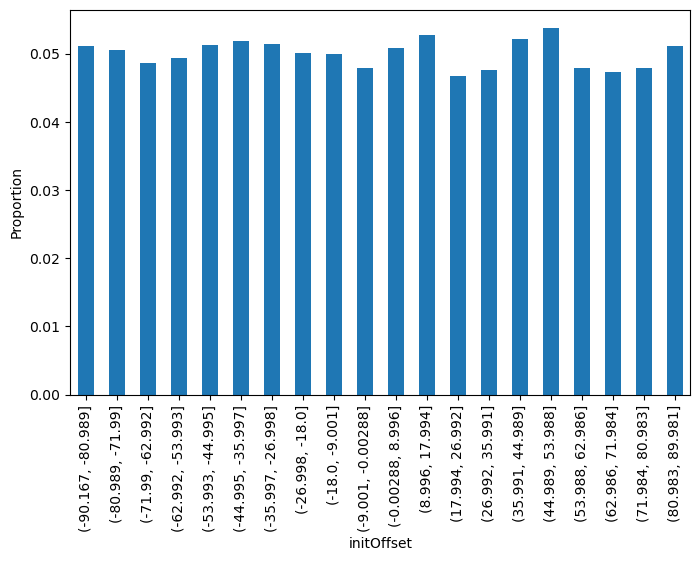

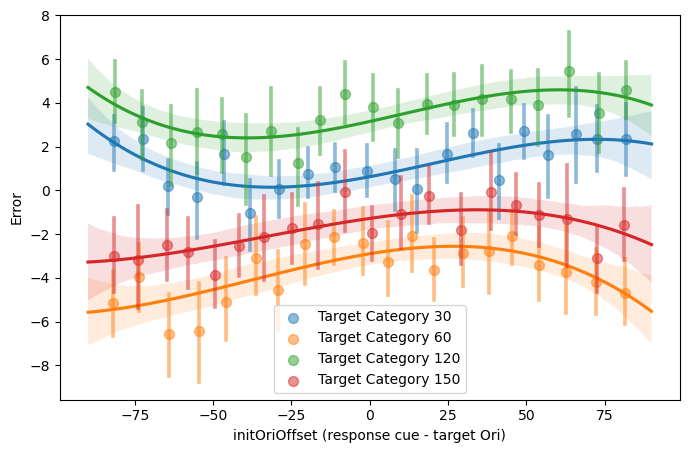

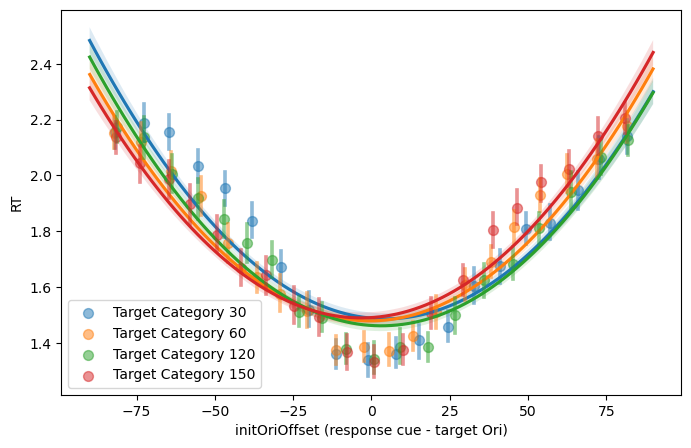

In [7]:
df_temp = df.copy()
# df_temp['errOri_nobias'] = np.nan
# Fit a 4th order polynomial to the error data and remove the bias for each subject
for i, sidx in enumerate(df_temp['subjID'].unique()):
    subdf = df_temp[df_temp['subjID'] == sidx]
    errorVals = subdf['errOri_scaled'].values
    
    # Fit a 4th order polynomial to the error data
    # x = subdf['targOriActual'].values
    # y = errorVals
    # model = np.poly1d(np.polyfit(x, y, 4))
    # yfit = model(x)
    # df_temp.loc[df_temp['subjID'] == sidx, 'errOri_scaled'] = errorVals - yfit

# Check if error depends on initial Ori
bin_labels = pd.cut(df_temp['initOffset'], bins=20)
bin_counts = bin_labels.value_counts(normalize=True).sort_index()
bin_counts.plot(kind='bar', figsize=(8, 5))
plt.xlabel('initOffset')
plt.ylabel('Proportion')
plt.show()

# Impact of initial orientation offset on error
plt.figure(figsize=(8, 5))
sns.regplot(x='initOffset', y='errOri_scaled', data=df_temp[df_temp['targOriCategory'] == 30], label='Target Category 30', scatter_kws={'alpha': 0.5}, x_bins=20, order=3)
sns.regplot(x='initOffset', y='errOri_scaled', data=df_temp[df_temp['targOriCategory'] == 60], label='Target Category 60', scatter_kws={'alpha': 0.5}, x_bins=20, order=3)
sns.regplot(x='initOffset', y='errOri_scaled', data=df_temp[df_temp['targOriCategory'] == 120], label='Target Category 120', scatter_kws={'alpha': 0.5}, x_bins=20, order=3)
sns.regplot(x='initOffset', y='errOri_scaled', data=df_temp[df_temp['targOriCategory'] == 150], label='Target Category 150', scatter_kws={'alpha': 0.5}, x_bins=20, order=3)
plt.legend()
plt.xlabel('initOriOffset (response cue - target Ori)')
plt.ylabel('Error')
plt.show()

# Impact of initial orientation offset on RT
plt.figure(figsize=(8, 5))
sns.regplot(x='initOffset', y='RT', data=df_temp[df_temp['targOriCategory'] == 30], label='Target Category 30', scatter_kws={'alpha': 0.5}, x_bins=20, order=2)
sns.regplot(x='initOffset', y='RT', data=df_temp[df_temp['targOriCategory'] == 60], label='Target Category 60', scatter_kws={'alpha': 0.5}, x_bins=20, order=2)
sns.regplot(x='initOffset', y='RT', data=df_temp[df_temp['targOriCategory'] == 120], label='Target Category 120', scatter_kws={'alpha': 0.5}, x_bins=20, order=2)
sns.regplot(x='initOffset', y='RT', data=df_temp[df_temp['targOriCategory'] == 150], label='Target Category 150', scatter_kws={'alpha': 0.5}, x_bins=20, order=2)
plt.legend()
plt.xlabel('initOriOffset (response cue - target Ori)')
plt.ylabel('RT')
plt.show()

# Observations:
# Error:
# Initial orientation offset has an impact on error in reported orientation
# For 30 and 120, errors are largely positive aka counterclockwise bias in reporting (i.e. bias towars 45 degree and 135 degree respectively)
# For 30 and 120, if initial offset is 0 to +45, errors are more biased towards 45/135, if initial offset is -45 to 0, the bias is removed
# For 30 and 120, if initial offset is +45 to +90, the bias is reduced, but if it is -45 to -90, the bias is increased

# For 60 and 150, errors are largely negative aka clockwise bias in reporting (i.e. bias towards 45 degree and 135 degree respectively)
# For 60, sweetspot is when response cue is 45 dgrees counterclockwise to target Ori, if it is more clockwise, reports are more biased towards 45
# Additionally, any response offset below 45, even if it is clockwise, reports are biased towards 45
# For 150, sweetspot is for a broader range between -45 and +45 and does not show a strong bias
# However, if response cue is 45 degrees ore more clockwise or counterclockwise, reports are biased towards 135

# RT:
# RT depends on initOffset severely. Faster responses when target Ori is close to initial Ori
# RT vs initOffset is quadratic in nature, looks symmetric for targOri 60 and 120, Looks asymmetric for targOri 30 and 150 
# for 30, slower than usual responses when response Cue is clockwise to target Ori
# for 150, slower than usual responses when response Cue is counterclockwise to target Ori
# Basically for 30 and 150, when response cue is downwards, RT decreases

In [ ]:
# Hunting for biases relative to horizontal and vertical meridians
fig, axes = plt.subplots(5, 2, figsize=(15, 20), sharey=True, sharex=True)

metric = 'errOri_scaled'
if metric == 'errOri_scaled':
    xlim = [-45, 45]
elif metric == 'abserrorOri':
    xlim = [0, 45]

# Iterate over the two values of stimPF
for i, stimPF_val in enumerate([0, 1]):
    df_temp = df[df['stimPF'] == stimPF_val].copy()

    idx30 = df_temp['targOriCategory'] == 30
    idx60 = df_temp['targOriCategory'] == 60
    idx120 = df_temp['targOriCategory'] == 120
    idx150 = df_temp['targOriCategory'] == 150

    # General cardinal bias
    df_temp_gen = df_temp.copy()
    df_temp_gen.loc[idx60, 'errOri_scaled'] = -df_temp_gen.loc[idx60, 'errOri_scaled']
    df_temp_gen.loc[idx150, 'errOri_scaled'] = -df_temp_gen.loc[idx150, 'errOri_scaled']
    sns.histplot(
        x=metric, data=df_temp_gen, bins=100, kde=True, palette='viridis', hue='TMSstatus',
        hue_order=['No TMS', 'TMS'], fill=False, stat='probability', common_norm=False, ax=axes[0, i]
    )
    axes[0, i].axvline(0, color='black', linestyle='--')
    axes[0, i].set_xlim(xlim)
    axes[0, i].set_title(f'General Cardinal Bias\nstimPF={stimPF_val}')
    axes[0, i].set_xlabel('Error')
    axes[0, i].set_ylabel('Proportion')

    # Horizontal cardinal bias
    df_temp_hor = df_temp.copy()
    df_temp_hor.loc[idx150, 'errOri_scaled'] = -df_temp_hor.loc[idx150, 'errOri_scaled']
    df_temp_hor = df_temp_hor[~idx60 & ~idx120]
    sns.histplot(
        x=metric, data=df_temp_hor, bins=100, kde=True, palette='viridis', hue='TMSstatus',
        hue_order=['No TMS', 'TMS'], fill=False, stat='probability', common_norm=False, ax=axes[1, i]
    )
    axes[1, i].axvline(0, color='black', linestyle='--')
    axes[1, i].set_xlim(xlim)
    axes[1, i].set_title(f'Horizontal Cardinal Bias\nstimPF={stimPF_val}')
    axes[1, i].set_xlabel('Error')
    axes[1, i].set_ylabel('Proportion')

    # Vertical cardinal bias
    df_temp_vert = df_temp.copy()
    df_temp_vert.loc[idx60, 'errOri_scaled'] = -df_temp_vert.loc[idx60, 'errOri_scaled']
    df_temp_vert = df_temp_vert[~idx30 & ~idx150]
    sns.histplot(
        x=metric, data=df_temp_vert, bins=100, kde=True, palette='viridis', hue='TMSstatus',
        hue_order=['No TMS', 'TMS'], fill=False, stat='probability', common_norm=False, ax=axes[2, i]
    )
    axes[2, i].axvline(0, color='black', linestyle='--')
    axes[2, i].set_xlim(xlim)
    axes[2, i].set_title(f'Vertical Cardinal Bias\nstimPF={stimPF_val}')
    axes[2, i].set_xlabel('Error')
    axes[2, i].set_ylabel('Proportion')

    # Bias towards diagonal while rotating clockwise
    df_temp_diag_cw = df_temp.copy()
    df_temo_diag_cw = df_temp_diag_cw[~idx60 & ~idx150]
    sns.histplot(
        x=metric, data=df_temp_diag_cw, bins=100, kde=True, palette='viridis', hue='TMSstatus',
        hue_order=['No TMS', 'TMS'], fill=False, stat='probability', common_norm=False, ax=axes[3, i]
    )
    axes[3, i].axvline(0, color='black', linestyle='--')
    axes[3, i].set_xlim(xlim)
    axes[3, i].set_title(f'Diagonal Bias (CW)\nstimPF={stimPF_val}')
    axes[3, i].set_xlabel('Error')
    axes[3, i].set_ylabel('Proportion')

    # Bias towards diagonal while rotating counterclockwise
    df_temp_diag_ccw = df_temp.copy()
    df_temp_diag_ccw.loc[idx60, 'errOri_scaled'] = -df_temp_diag_ccw.loc[idx60, 'errOri_scaled']
    df_temp_diag_ccw.loc[idx150, 'errOri_scaled'] = -df_temp_diag_ccw.loc[idx150, 'errOri_scaled']
    df_temp_diag_ccw = df_temp_diag_ccw[~idx30 & ~idx120]
    sns.histplot(
        x=metric, data=df_temp_diag_ccw, bins=100, kde=True, palette='viridis', hue='TMSstatus',
        hue_order=['No TMS', 'TMS'], fill=False, stat='probability', common_norm=False, ax=axes[4, i]
    )
    axes[4, i].axvline(0, color='black', linestyle='--')
    axes[4, i].set_xlim(xlim)
    axes[4, i].set_title(f'Diagonal Bias (CCW)\nstimPF={stimPF_val}')
    axes[4, i].set_xlabel('Error')
    axes[4, i].set_ylabel('Proportion')

plt.tight_layout()
plt.show()

In [ ]:
results = {
    'subjID': [],
    'stimPF': [],
    'TMSstatus': [],
    'general_cardinal_mean': [],
    'horizontal_cardinal_mean': [],
    'vertical_cardinal_mean': [],
    'general_cardinal_var': [],
    'horizontal_cardinal_var': [],
    'vertical_cardinal_var': []
}

for subj in df['subjID'].unique():
    for stimPF_val in [0, 1]:
        for tms_status in df['TMSstatus'].unique():
            df_temp = df[(df['subjID'] == subj) & (df['stimPF'] == stimPF_val) & (df['TMSstatus'] == tms_status)].copy()

            idx30 = df_temp['targOriCategory'] == 30
            idx60 = df_temp['targOriCategory'] == 60
            idx120 = df_temp['targOriCategory'] == 120
            idx150 = df_temp['targOriCategory'] == 150

            # General cardinal bias
            df_temp_gen = df_temp.copy()
            df_temp_gen.loc[idx60, 'errOri_scaled'] = -df_temp_gen.loc[idx60, 'errOri_scaled']
            df_temp_gen.loc[idx150, 'errOri_scaled'] = -df_temp_gen.loc[idx150, 'errOri_scaled']
            general_stats = circ_stats(df_temp_gen['errOri_scaled'].values)
            general_mean = general_stats[0]
            general_var = general_stats[2]

            # Horizontal cardinal bias
            df_temp_hor = df_temp.copy()
            df_temp_hor.loc[idx150, 'errOri_scaled'] = -df_temp_hor.loc[idx150, 'errOri_scaled']
            df_temp_hor = df_temp_hor[~idx60 & ~idx120]
            horizontal_stats = circ_stats(df_temp_hor['errOri_scaled'].values)
            horizontal_mean = horizontal_stats[0]
            horizontal_var = horizontal_stats[2]

            # Vertical cardinal bias
            df_temp_vert = df_temp.copy()
            df_temp_vert.loc[idx60, 'errOri_scaled'] = -df_temp_vert.loc[idx60, 'errOri_scaled']
            df_temp_vert = df_temp_vert[~idx30 & ~idx150]
            vertical_stats = circ_stats(df_temp_vert['errOri_scaled'].values)
            vertical_mean = vertical_stats[0]
            vertical_var = vertical_stats[2]

            # Store the results
            results['subjID'].append(subj)
            results['stimPF'].append(stimPF_val)
            results['TMSstatus'].append(tms_status)
            results['general_cardinal_mean'].append(general_mean)
            results['horizontal_cardinal_mean'].append(horizontal_mean)
            results['vertical_cardinal_mean'].append(vertical_mean)
            results['general_cardinal_var'].append(general_var)
            results['horizontal_cardinal_var'].append(horizontal_var)
            results['vertical_cardinal_var'].append(vertical_var)

results_df = pd.DataFrame(results)

# Plot the results
fig, axes = plt.subplots(2, 2, figsize=(10, 10))

sns.barplot(x='TMSstatus', y='general_cardinal_mean', data=results_df, hue='stimPF', ax=axes[0, 0])
sns.stripplot(x='TMSstatus', y='general_cardinal_mean', data=results_df, hue='stimPF', ax=axes[0, 0], dodge=True)
axes[0, 0].set_title('General Cardinal Bias')

sns.barplot(x='TMSstatus', y='horizontal_cardinal_mean', data=results_df, hue='stimPF', ax=axes[0, 1])
sns.stripplot(x='TMSstatus', y='horizontal_cardinal_mean', data=results_df, hue='stimPF', ax=axes[0, 1], dodge=True)
axes[0, 1].set_title('Horizontal Cardinal Bias')

sns.barplot(x='TMSstatus', y='vertical_cardinal_mean', data=results_df, hue='stimPF', ax=axes[1, 0])
sns.stripplot(x='TMSstatus', y='vertical_cardinal_mean', data=results_df, hue='stimPF', ax=axes[1, 0], dodge=True)
axes[1, 0].set_title('Vertical Cardinal Bias')

plt.tight_layout()
plt.show()

# Perform rmANOVA on the results
from pingouin import rm_anova
from scipy import stats
results_df['subjID'] = results_df['subjID'].astype(str)
results_df['stimPF'] = results_df['stimPF'].astype(str)
results_df['TMSstatus'] = results_df['TMSstatus'].astype(str)

print('ANOVA for general cardinal bias')
aov = rm_anova(data=results_df, dv='general_cardinal_mean', within=['stimPF', 'TMSstatus'], subject='subjID')
print(aov)

print('ANOVA for horizontal cardinal bias')
aov = rm_anova(data=results_df, dv='horizontal_cardinal_mean', within=['stimPF', 'TMSstatus'], subject='subjID')
print(aov)

print('ANOVA for vertical cardinal bias')
aov = rm_anova(data=results_df, dv='vertical_cardinal_mean', within=['stimPF', 'TMSstatus'], subject='subjID')
print(aov)

# Perform t-tests
# General cardinal bias for TMS (inPF vs outPF)
tms_inPF = results_df[(results_df['stimPF'] == 1) & (results_df['TMSstatus'] == 'TMS')]['general_cardinal_mean']
tms_outPF = results_df[(results_df['stimPF'] == 0) & (results_df['TMSstatus'] == 'TMS')]['general_cardinal_mean']
t, p = stats.ttest_rel(tms_inPF, tms_outPF)
print(f'TMS General Cardinal Bias inPF vs outPF: t={t}, p={p}')

# Vertical cardinal bias for TMS (inPF vs outPF)
tms_inPF = results_df[(results_df['stimPF'] == 1) & (results_df['TMSstatus'] == 'TMS')]['vertical_cardinal_mean']
tms_outPF = results_df[(results_df['stimPF'] == 0) & (results_df['TMSstatus'] == 'TMS')]['vertical_cardinal_mean']
t, p = stats.ttest_rel(tms_inPF, tms_outPF)
print(f'TMS Vertical Cardinal Bias inPF vs outPF: t={t}, p={p}')


In [ ]:
# Check error per orientation group and TMS condition
df_temp = df[(df['abserrorOri'] < 3 * df['abserrorOri'].std()) & (df['stimPF'] == 1)]
ori_tms_grouped = df_temp.groupby(['subjID', 'TMScond_label', 'targOriCategory'], observed=False).agg(
    mean_error=('abserrorOri', 'mean'),
    sem_mean=('abserrorOri', 'sem'),
    std_error=('errOri_scaled', lambda data: circ_stats(data)[1]),
    bias_error=('errOri_scaled', lambda data: circ_stats(data)[0])
    ).reset_index()


f, axs = plt.subplots(3, 1, figsize=(15, 15))
sns.barplot(x='targOriCategory', y='mean_error', hue='TMScond_label', data=ori_tms_grouped, ax=axs[0], errorbar='se',
            hue_order=['No TMS', 'Early TMS', 'Middle TMS'])
axs[0].set_title('Mean error')
axs[0].set_xlabel('Target Orientation')

sns.barplot(x='targOriCategory', y='std_error', hue='TMScond_label', data=ori_tms_grouped, ax=axs[1], errorbar='se',
            hue_order=['No TMS', 'Early TMS', 'Middle TMS'])
axs[1].set_title('Circular Standard Deviation')
axs[1].set_xlabel('Target Orientation')

sns.barplot(x='targOriCategory', y='bias_error', hue='TMScond_label', data=ori_tms_grouped, ax=axs[2], errorbar='se',
            hue_order=['No TMS', 'Early TMS', 'Middle TMS'])
axs[2].set_title('Circular Bias')
axs[2].set_xlabel('Target Orientation')

f.tight_layout()

handles, labels = axs[0].get_legend_handles_labels()
f.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, -0.05), ncol=len(labels))
axs[0].legend_.remove()
axs[1].legend_.remove()
axs[2].legend_.remove()

plt.show()

# Perform rmANOVA on mean_error 
aov = AnovaRM(ori_tms_grouped, 'mean_error', 'subjID', within=['TMScond_label', 'targOriCategory'])
res = aov.fit()
print(res)

# Perform rmANOVA on std_error
aov = AnovaRM(ori_tms_grouped, 'std_error', 'subjID', within=['TMScond_label', 'targOriCategory'])
res = aov.fit()
print(res)

# Perform rmANOVA on bias_error
aov = AnovaRM(ori_tms_grouped, 'bias_error', 'subjID', within=['TMScond_label', 'targOriCategory'])
res = aov.fit()
print(res)

In [ ]:
import statsmodels.formula.api as smf
import statsmodels.api as sm
df_temp = df[(df['abserrorOri'] < 3 * df['abserrorOri'].std())]
ori_tms_grouped = df_temp.groupby(['subjID', 'TMScond_label', 'stimPF', 'targOriCategory'], observed=False).agg(
    mean_error=('abserrorOri', 'mean'),
    sem_mean=('abserrorOri', 'sem'),
    std_error=('errOri_scaled', lambda data: circ_stats(data)[1]),
    bias_error=('errOri_scaled', lambda data: circ_stats(data)[0])
    ).reset_index()

model_mean_error = smf.mixedlm("mean_error ~ C(TMScond_label, Sum) * C(stimPF, Treatment(0))",
                               ori_tms_grouped, 
                               groups=ori_tms_grouped['subjID'],
                               re_formula="~  C(targOriCategory, Sum)").fit()

# Model for std_error
model_std_error = smf.mixedlm("std_error ~ C(TMScond_label, Sum) * C(stimPF, Treatment(0))",
                                ori_tms_grouped,
                                groups=ori_tms_grouped['subjID'],
                                re_formula="~  C(targOriCategory, Sum)").fit()
# Model for bias_error
model_bias_error = smf.mixedlm("bias_error ~ C(TMScond_label, Sum) * C(stimPF, Treatment(0))",
                                ori_tms_grouped,
                                groups=ori_tms_grouped['subjID'],
                                re_formula="~  C(targOriCategory, Sum)").fit()

# Print the summary of each model
print("Mean Error Model Results:\n", model_mean_error.summary())
print("\nStandard Error Model Results:\n", model_std_error.summary())
print("\nBias Error Model Results:\n", model_bias_error.summary())

In [ ]:
# Create 3 subplots plotting target and final orientation by TMS condition
df_temp = df.copy()
df_temp = df_temp[df_temp['abserrorOri'] < 3 * df_temp['abserrorOri'].std()]
f, axs = plt.subplots(3, 1, figsize=(10, 15))
sns.scatterplot(x='targOriActual', y='finalOri', data=df_temp[df_temp['TMScond_label'] == 'No TMS'], ax=axs[0])
axs[0].plot([0, 180], [0, 180], 'k--')
axs[0].set_title('No TMS')

sns.scatterplot(x='targOriActual', y='finalOri', data=df_temp[df_temp['TMScond_label'] == 'Early TMS'], ax=axs[1])
axs[1].plot([0, 180], [0, 180], 'k--')
axs[1].set_title('Early TMS')

sns.scatterplot(x='targOriActual', y='finalOri', data=df_temp[df_temp['TMScond_label'] == 'Middle TMS'], ax=axs[2])
axs[2].plot([0, 180], [0, 180], 'k--')
axs[2].set_title('Middle TMS')

f.tight_layout()
plt.show()

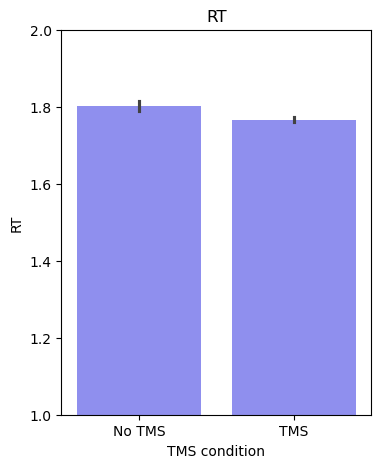

                 Anova
          F Value Num DF  Den DF Pr > F
---------------------------------------
TMSstatus  1.8407 1.0000 22.0000 0.1886



In [8]:
# Check if TMS impacts RT
temp_df = df.copy()
# temp_df['RT'] = np.log(temp_df['RT'])
plt.figure(figsize=(4, 5))
sns.barplot(x='TMSstatus', y='RT', data=temp_df[temp_df['stimPF'] == 1], errorbar='se', order=['No TMS', 'TMS'], color='blue', alpha=0.5)
plt.ylim([1, 2])
plt.xlabel('TMS condition')
plt.title('RT')
# plt.ylabel('RT')
# plt.title('Impact of TMS on RT')
plt.show()

# Perform repeated measures ANOVA on RT
gp_df = temp_df[temp_df['stimPF'] == 1].groupby(['subjID', 'TMSstatus'], observed=False).agg(
    mean_RT=('RT', 'mean'),
    sem_RT=('RT', 'sem')).reset_index()
aovrm = AnovaRM(gp_df, 'mean_RT', 'subjID', within=['TMSstatus'])
res = aovrm.fit()
print(res)

In [ ]:
# Simulate two bar plots with error bars, one for TMS and one for No TMS
# showing "predicted performance" to be worse for TMS
# Simulate data
np.random.seed(0)
n = 100
x = np.linspace(0, 4, n)
y = 3 * x + np.random.normal(0, 1, n)
dfSim = pd.DataFrame({'x': x, 'y': y})
dfSim['TMSstatus'] = np.random.choice(['No TMS', 'TMS'], n)
dfSim['y'] = dfSim['y'] + np.where(dfSim['TMSstatus'] == 'TMS', 1, 0)

# Plot the data
plt.figure(figsize=(6, 5))
sns.barplot(x='TMSstatus', y='y', data=dfSim, color='blue', alpha=0.5, errorbar='se')
plt.xlabel('TMS status')
plt.ylabel('Performance')
plt.show()

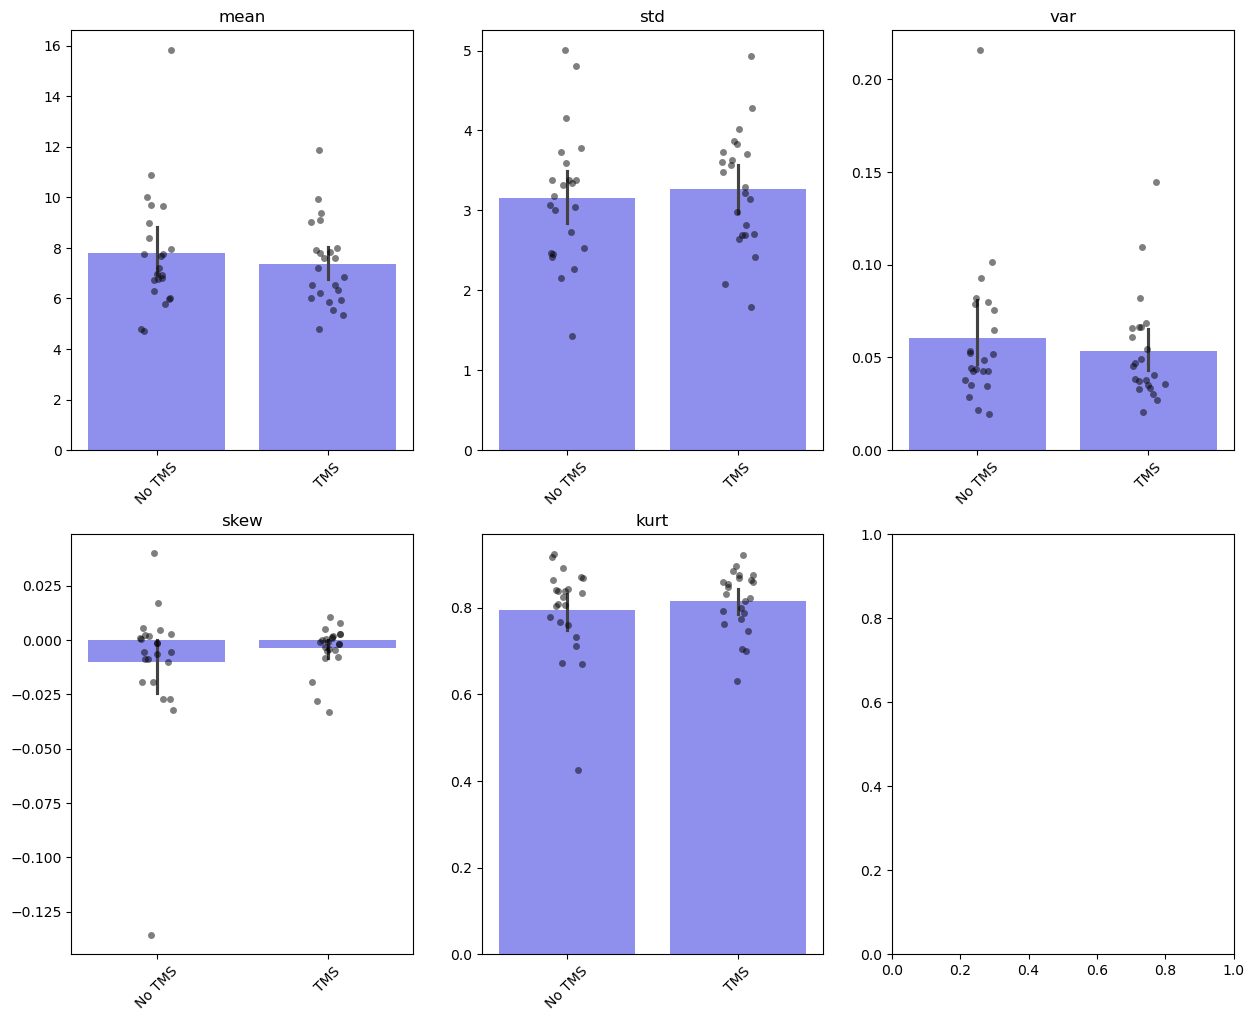

T-test results for mean: t=2.099208301831758, p=0.04749415165115455
T-test results for std: t=-1.436746798170201, p=0.16485992279230383
T-test results for var: t=2.0854421651080206, p=0.048841378216772535
T-test results for skew: t=-1.1978372779718145, p=0.24372676690959513
T-test results for kurt: t=-2.139891095312907, p=0.043705800095544756


In [9]:
# Model-free: Population
from scipy import stats
summaryData = np.empty((len(df['subjID'].unique()), 5, 2))
orderStats = ['mean', 'std', 'var', 'skew', 'kurt']
metric_to_plot = 'errOri_scaled'
for i, sidx in enumerate(df['subjID'].unique()):
    sTemp = df[(df['subjID'] == sidx) & (df['stimPF'] == 1)]
    sTemp = sTemp[sTemp['abserrorOri'] < 5 * sTemp['abserrorOri'].std()]
    # sTemo = sTemp[(sTemp['initOffset'] > 25) | (sTemp['initOffset'] < -25)]
    
    nt_df = sTemp[sTemp['TMSstatus'] == 'No TMS']
    t_df = sTemp[sTemp['TMSstatus'] == 'TMS']

    nt_mean, nt_std, nt_var, nt_skew, nt_kurt = circ_stats(nt_df[metric_to_plot])
    t_mean, t_std, t_var, t_skew, t_kurt = circ_stats(t_df[metric_to_plot])

    nt_mean = nt_df['abserrorOri'].mean()
    t_mean = t_df['abserrorOri'].mean()

    summaryData[i, :, :] = np.array([[nt_mean, 1/nt_std, nt_var, nt_skew, nt_kurt], [t_mean, 1/t_std, t_var, t_skew, t_kurt]]).T

f, axs = plt.subplots(2, 3, figsize=(15, 12))
axs = axs.flatten()
for i in range(5):
    sns.stripplot(data=summaryData[:, i, :], ax=axs[i], color='black', alpha=0.5, jitter=0.1)
    sns.barplot(data=summaryData[:, i, :], ax=axs[i], color='blue', linewidth=1, alpha=0.5)
    axs[i].set_xticks([0, 1])
    axs[i].set_xticklabels(['No TMS', 'TMS'], rotation=45)
    axs[i].set_title(f'{orderStats[i]}')
plt.show()

# # Perform repeated measures ANOVA for each metric
# metrics = ['mean', 'std', 'var', 'skew', 'kurt']
# results = {}

# for i, metric in enumerate(metrics):
#     # Reshape data: Each row corresponds to a subject's score in each condition
#     data = pd.DataFrame({
#         'subject': np.repeat(np.arange(len(df['subjID'].unique())), 2),
#         'TMS_condition': np.tile(['No TMS', 'TMS'], len(df['subjID'].unique())),
#         'metric_value': summaryData[:, i, :].flatten()
#     })

#     # Perform repeated measures ANOVA
#     anova_result = AnovaRM(data, 'metric_value', 'subject', within=['TMSstatus']).fit()
#     results[metric] = anova_result

# # Print ANOVA results
# for metric, result in results.items():
#     print(f"ANOVA results for {metric}:")
#     print(result)
#     print("\n")

# Perform paired t-test for each metric
metrics = ['mean', 'std', 'var', 'skew', 'kurt']
results = {}

for i, metric in enumerate(metrics):
    # Perform paired t-test
    t_stat, p_val = stats.ttest_rel(summaryData[:, i, 0], summaryData[:, i, 1])
    results[metric] = (t_stat, p_val)

# Print t-test results
for metric, result in results.items():
    print(f"T-test results for {metric}: t={result[0]}, p={result[1]}")

# Conclusion:
# TMS has impact on precision of reported orientation but not on accuracy.
# Specifically, TMS reduces precision of memory and the impact is larger for early TMS compared to middle TMS

Subject 3 has higher std in inPF than outPF
4
Subject 8 has higher std in inPF than outPF
Subject 14 has higher std in inPF than outPF
Subject 23 has higher std in inPF than outPF
Subject 24 has higher std in inPF than outPF
Subject 25 has higher std in inPF than outPF
Subject 28 has higher std in inPF than outPF


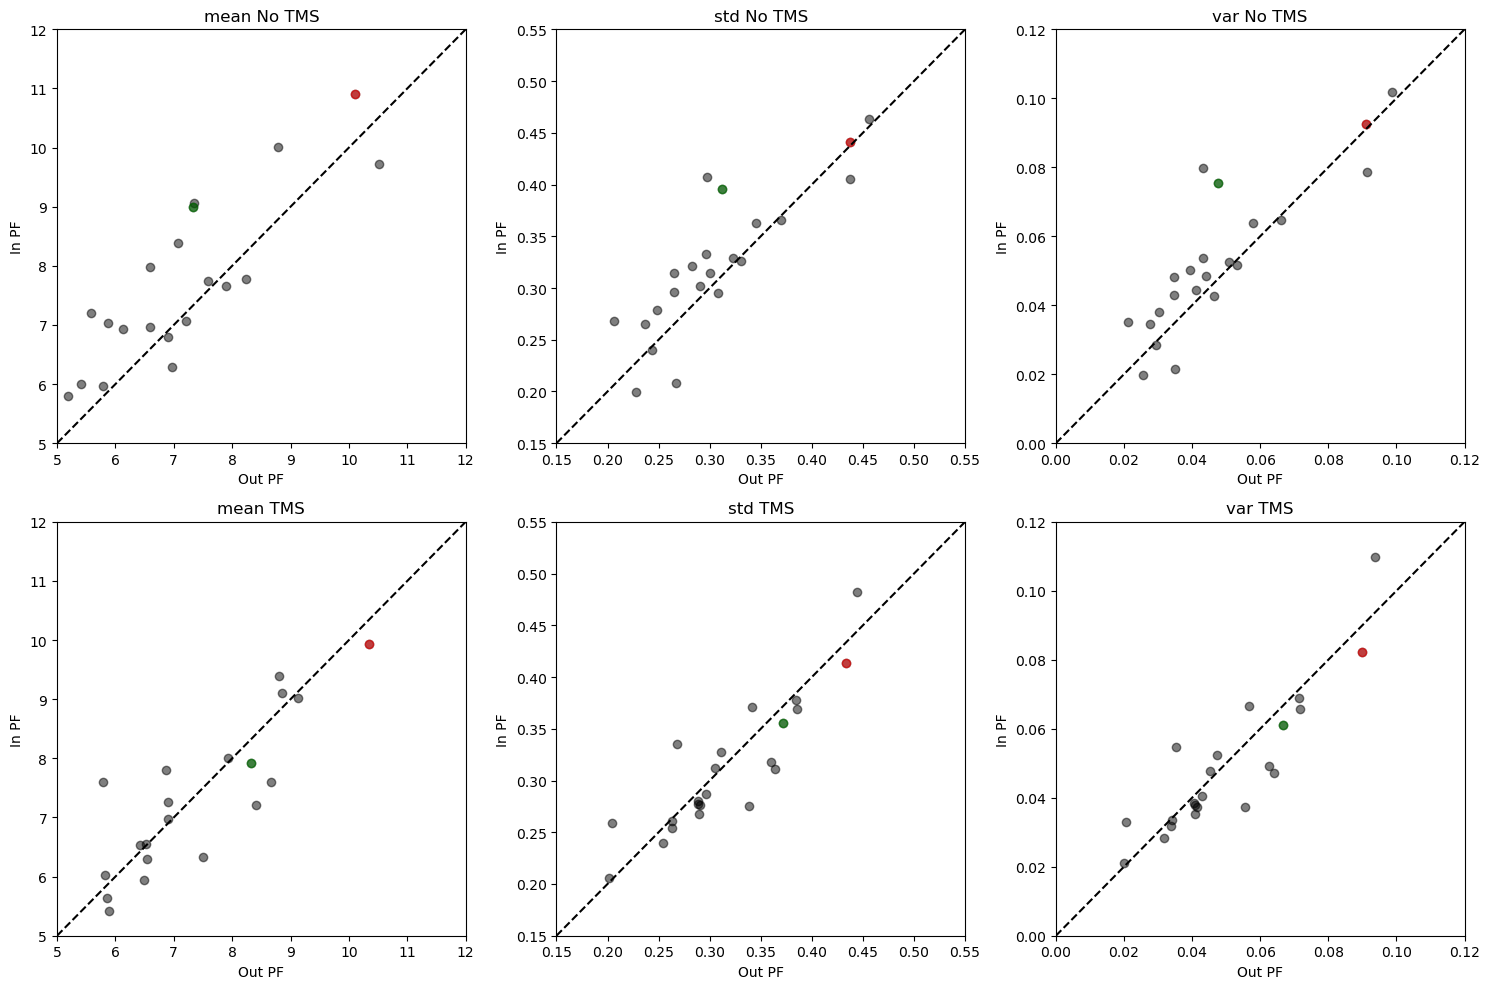

In [17]:
orderStats = ['mean', 'std', 'var', 'skew', 'kurt']
metric_to_plot = 'errOri_scaled'
summaryData_inPF = np.empty((len(df['subjID'].unique()), 5, 2))
summaryData_outPF = np.empty((len(df['subjID'].unique()), 5, 2))

for i, sidx in enumerate(df['subjID'].unique()):
    if sidx == 6:
        print(i)
    sTemp = df[(df['subjID'] == sidx)] # Get the subject dataframe
    sTemp = sTemp[sTemp['abserrorOri'] < 5 * sTemp['abserrorOri'].std()] # Remove outliers

    # Get the data for inPF and outPF
    ntIn = sTemp[(sTemp['stimPF'] == 1) & (sTemp['TMSstatus'] == 'No TMS')]
    tIn = sTemp[(sTemp['stimPF'] == 1) & (sTemp['TMSstatus'] == 'TMS')]
    ntOut = sTemp[(sTemp['stimPF'] == 0) & (sTemp['TMSstatus'] == 'No TMS')]
    tOut = sTemp[(sTemp['stimPF'] == 0) & (sTemp['TMSstatus'] == 'TMS')]

    summaryData_inPF[i, :, 0] = circ_stats(ntIn[metric_to_plot])
    summaryData_inPF[i, :, 1] = circ_stats(tIn[metric_to_plot])
    summaryData_outPF[i, :, 0] = circ_stats(ntOut[metric_to_plot])
    summaryData_outPF[i, :, 1] = circ_stats(tOut[metric_to_plot])

    # Update means with absolute error
    summaryData_inPF[i, 0, 0] = ntIn['abserrorOri'].mean()
    summaryData_inPF[i, 0, 1] = tIn['abserrorOri'].mean()
    summaryData_outPF[i, 0, 0] = ntOut['abserrorOri'].mean()
    summaryData_outPF[i, 0, 1] = tOut['abserrorOri'].mean()

    # if ntIn['abserrorOri'].mean() < ntOut['abserrorOri'].mean():
    #     print(f'Subject {sidx} has lower error in inPF than outPF')

    # if summaryData_inPF[i, 1, 0] < summaryData_outPF[i, 1, 0]:
    #     print(f'Subject {sidx} has lower std in inPF than outPF')

    if summaryData_inPF[i, 1, 1] > summaryData_outPF[i, 1, 1]:
        print(f'Subject {sidx} has higher std in inPF than outPF')




    # sTemp = df[(df['subjID'] == sidx) & (df['stimPF'] == 1)]
    # sTemp = sTemp[sTemp['abserrorOri'] < 5 * sTemp['abserrorOri'].std()]
    # # sTemp = sTemp[(sTemp['initOffset'] > 25) | (sTemp['initOffset'] < -25)]
    
    # nt_df = sTemp[sTemp['TMSstatus'] == 'No TMS']
    # t_df = sTemp[sTemp['TMSstatus'] == 'TMS']

    # nt_mean, nt_std, nt_var, nt_skew, nt_kurt = circ_stats(nt_df[metric_to_plot])
    # t_mean, t_std, t_var, t_skew, t_kurt = circ_stats(t_df[metric_to_plot])

    # in_nt_mean = nt_mean

    # nt_mean = nt_df['abserrorOri'].mean()
    # t_mean = t_df['abserrorOri'].mean()

    # summaryData_inPF[i, :, :] = np.array([[nt_mean, 1/nt_std, nt_var, nt_skew, nt_kurt], [t_mean, 1/t_std, t_var, t_skew, t_kurt]]).T

    # sTemp = df[(df['subjID'] == sidx) & (df['stimPF'] == 0)]
    # sTemp = sTemp[sTemp['abserrorOri'] < 5 * sTemp['abserrorOri'].std()]
    # # sTemp = sTemp[(sTemp['initOffset'] > 25) | (sTemp['initOffset'] < -25)]

    # nt_df = sTemp[sTemp['TMSstatus'] == 'No TMS']
    # t_df = sTemp[sTemp['TMSstatus'] == 'TMS']

    # nt_mean, nt_std, nt_var, nt_skew, nt_kurt = circ_stats(nt_df[metric_to_plot])
    # t_mean, t_std, t_var, t_skew, t_kurt = circ_stats(t_df[metric_to_plot])

    # if in_nt_mean > nt_mean:
    #     print(f'subject {sidx} has lower error in inPF than outPF')

    # nt_mean = nt_df['abserrorOri'].mean()
    # t_mean = t_df['abserrorOri'].mean()

    # summaryData_outPF[i, :, :] = np.array([[nt_mean, 1/nt_std, nt_var, nt_skew, nt_kurt], [t_mean, 1/t_std, t_var, t_skew, t_kurt]]).T

f, axs = plt.subplots(2, 3, figsize=(15, 10))  # Changed to 2 rows and 3 columns

for i in range(3):
    # Set limits based on the index
    if i == 0:
        limMin, limMax = 5, 12
    elif i == 1:
        limMin, limMax = 0.15, 0.55 # 2, 6 #
    elif i == 2:
        limMin, limMax = 0, 0.12
    
    # Plot for No TMS
    axs[0, i].scatter(summaryData_outPF[:, i, 0], summaryData_inPF[:, i, 0], color='black', alpha=0.5)
    axs[0, i].scatter(summaryData_outPF[4, i, 0], summaryData_inPF[4, i, 0], color='red', alpha=0.5)
    axs[0, i].scatter(summaryData_outPF[1, i, 0], summaryData_inPF[1, i, 0], color='green', alpha=0.5)
    axs[0, i].set_title(f'{orderStats[i]} No TMS')
    axs[0, i].set_xlabel('Out PF')
    axs[0, i].set_ylabel('In PF')
    axs[0, i].plot([limMin, limMax], [limMin, limMax], 'k--')
    axs[0, i].set_xlim(limMin, limMax)
    axs[0, i].set_ylim(limMin, limMax)

    # Plot for TMS
    axs[1, i].scatter(summaryData_outPF[:, i, 1], summaryData_inPF[:, i, 1], color='black', alpha=0.5)
    axs[1, i].scatter(summaryData_outPF[4, i, 1], summaryData_inPF[4, i, 1], color='red', alpha=0.5)
    axs[1, i].scatter(summaryData_outPF[1, i, 1], summaryData_inPF[1, i, 1], color='green', alpha=0.5)
    axs[1, i].set_title(f'{orderStats[i]} TMS')
    axs[1, i].set_xlabel('Out PF')
    axs[1, i].set_ylabel('In PF')
    axs[1, i].plot([limMin, limMax], [limMin, limMax], 'k--')
    axs[1, i].set_xlim(limMin, limMax)
    axs[1, i].set_ylim(limMin, limMax)

plt.tight_layout()  # Adjust layout for better spacing
plt.show()

In [ ]:
df_temp.head(20)

,subjID,day,block,TMScond,stimPF,targOriCategory,targOriActual,stimSize,targX,targY,rho,polang,initDuration,sampleDuration,delay1Duration,delay2Duration,respDuration,feedbackDuration,itiDuration,trialDuration,initOri,oriArray_1,oriArray_2,oriArray_3,oriArray_4,oriArray_5,oriArray_6,oriArray_7,oriArray_8,oriArray_9,oriArray_10,oriArray_11,oriArray_12,oriArray_13,oriArray_14,oriArray_15,oriArray_16,oriArray_17,oriArray_18,oriArray_19,oriArray_20,oriArray_21,oriArray_22,oriArray_23,oriArray_24,oriArray_25,oriArray_26,oriArray_27,oriArray_28,oriArray_29,oriArray_30,oriArray_31,oriArray_32,oriArray_33,oriArray_34,oriArray_35,oriArray_36,oriArray_37,oriArray_38,oriArray_39,oriArray_40,oriArray_41,oriArray_42,oriArray_43,oriArray_44,oriArray_45,oriArray_46,oriArray_47,oriArray_48,oriArray_49,oriArray_50,oriArray_51,oriArray_52,oriArray_53,oriArray_54,oriArray_55,oriArray_56,oriArray_57,oriArray_58,oriArray_59,oriArray_60,oriArray_61,oriArray_62,oriArray_63,oriArray_64,oriArray_65,oriArray_66,oriArray_67,oriArray_68,oriArray_69,oriArray_70,oriArray_71,oriArray_72,oriArray_73,oriArray_74,oriArray_75,oriArray_76,oriArray_77,oriArray_78,oriArray_79,oriArray_80,oriArray_81,oriArray_82,oriArray_83,oriArray_84,oriArray_85,oriArray_86,oriArray_87,oriArray_88,oriArray_89,oriArray_90,oriArray_91,oriArray_92,oriArray_93,oriArray_94,oriArray_95,oriArray_96,oriArray_97,oriArray_98,oriArray_99,oriArray_100,oriArray_101,oriArray_102,oriArray_103,oriArray_104,oriArray_105,oriArray_106,oriArray_107,oriArray_108,oriArray_109,oriArray_110,oriArray_111,oriArray_112,oriArray_113,oriArray_114,oriArray_115,oriArray_116,oriArray_117,oriArray_118,oriArray_119,oriArray_120,finalOri,RT,errorOri,subjInitials,hemisphereStimulated,PT,oriArray_121,oriSteps,initOffset,errOri_scaled,abserrorOri,stimPF_label,TMScond_label,TMSstatus
0,1,1,1,3,1,150,150.4502,182,1264.895,691.8237,340.6045,26.4712,1.0002,0.2502,2.0002,2.0003,1.3968,1.0005,1.5002,9.1502,127.0883,127.0883,127.0883,127.0883,127.0883,127.0883,127.0883,127.0883,127.0883,127.0883,127.0883,127.0883,127.0883,127.0883,127.0883,127.0883,127.0883,127.0883,127.0883,127.0883,127.0883,127.0883,128.0883,129.0883,130.0883,131.0883,133.0883,133.0883,135.0883,136.0883,136.0883,137.0883,139.0883,140.0883,141.0883,141.0883,141.0883,141.0883,141.0883,141.0883,141.0883,141.0883,141.0883,141.0883,141.0883,141.0883,141.0883,141.0883,141.0883,141.0883,141.0883,141.0883,141.0883,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,141.0883,1.3240,9.3619,MRD1219,Left,42.0,NaN,52,-23.3619,-9.3619,9.3619,inPF,Middle TMS,TMS
1,1,1,1,3,1,150,141.0927,182,1264.895,691.8237,340.6045,26.4712,1.0003,0.2502,2.0002,2.0002,1.2362,1.0002,1.5003,8.9890,171.0400,171.0400,171.0400,171.0400,171.0400,171.0400,171.0400,171.0400,171.0400,171.0400,171.0400,171.0400,171.0400,171.0400,171.0400,171.0400,171.0400,171.0400,171.0400,171.0400,169.0400,166.0400,163.0400,161.0400,158.0400,155.0400,152.0400,148.0400,145.0400,141.0400,139.0400,138.0400,136.0400,135.0400,135.0400,135.0400,135.0400,135.0400,135.0400,135.0400,135.0400,135.0400,135.0400,135.0400,135.0400,135.0400,135.0400,135.0400,135.0400,135.0400,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,135.0400,1.2067,6.0527,MRD1219,Left,42.0,NaN,49,29.9473,-6.0527,6.0527,inPF,Middle TMS,TMS
2,1,1,1,3,0,30,39.4616,182,655.105,691.8237,340.6045,153.5288,1.0003,0.2502,2.0002,2.0002,1.1356,1.0002,2.5002,9.8879,80.2055,80.2055,80.2055,80.2055,80.2055,80.2055,80.2055,80.2055,80.2055,80.2055,80.2055,80.2055,80.2055,80.2055,80.2055,80.2055,80.2055,79.2055,77.2055,7

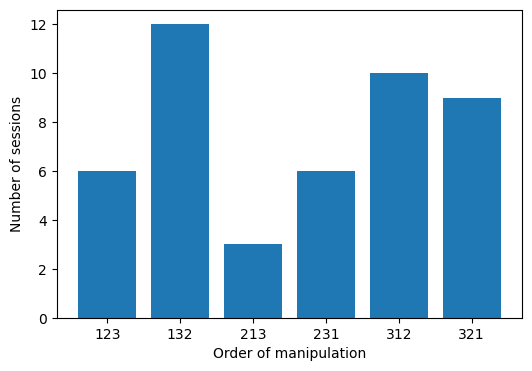

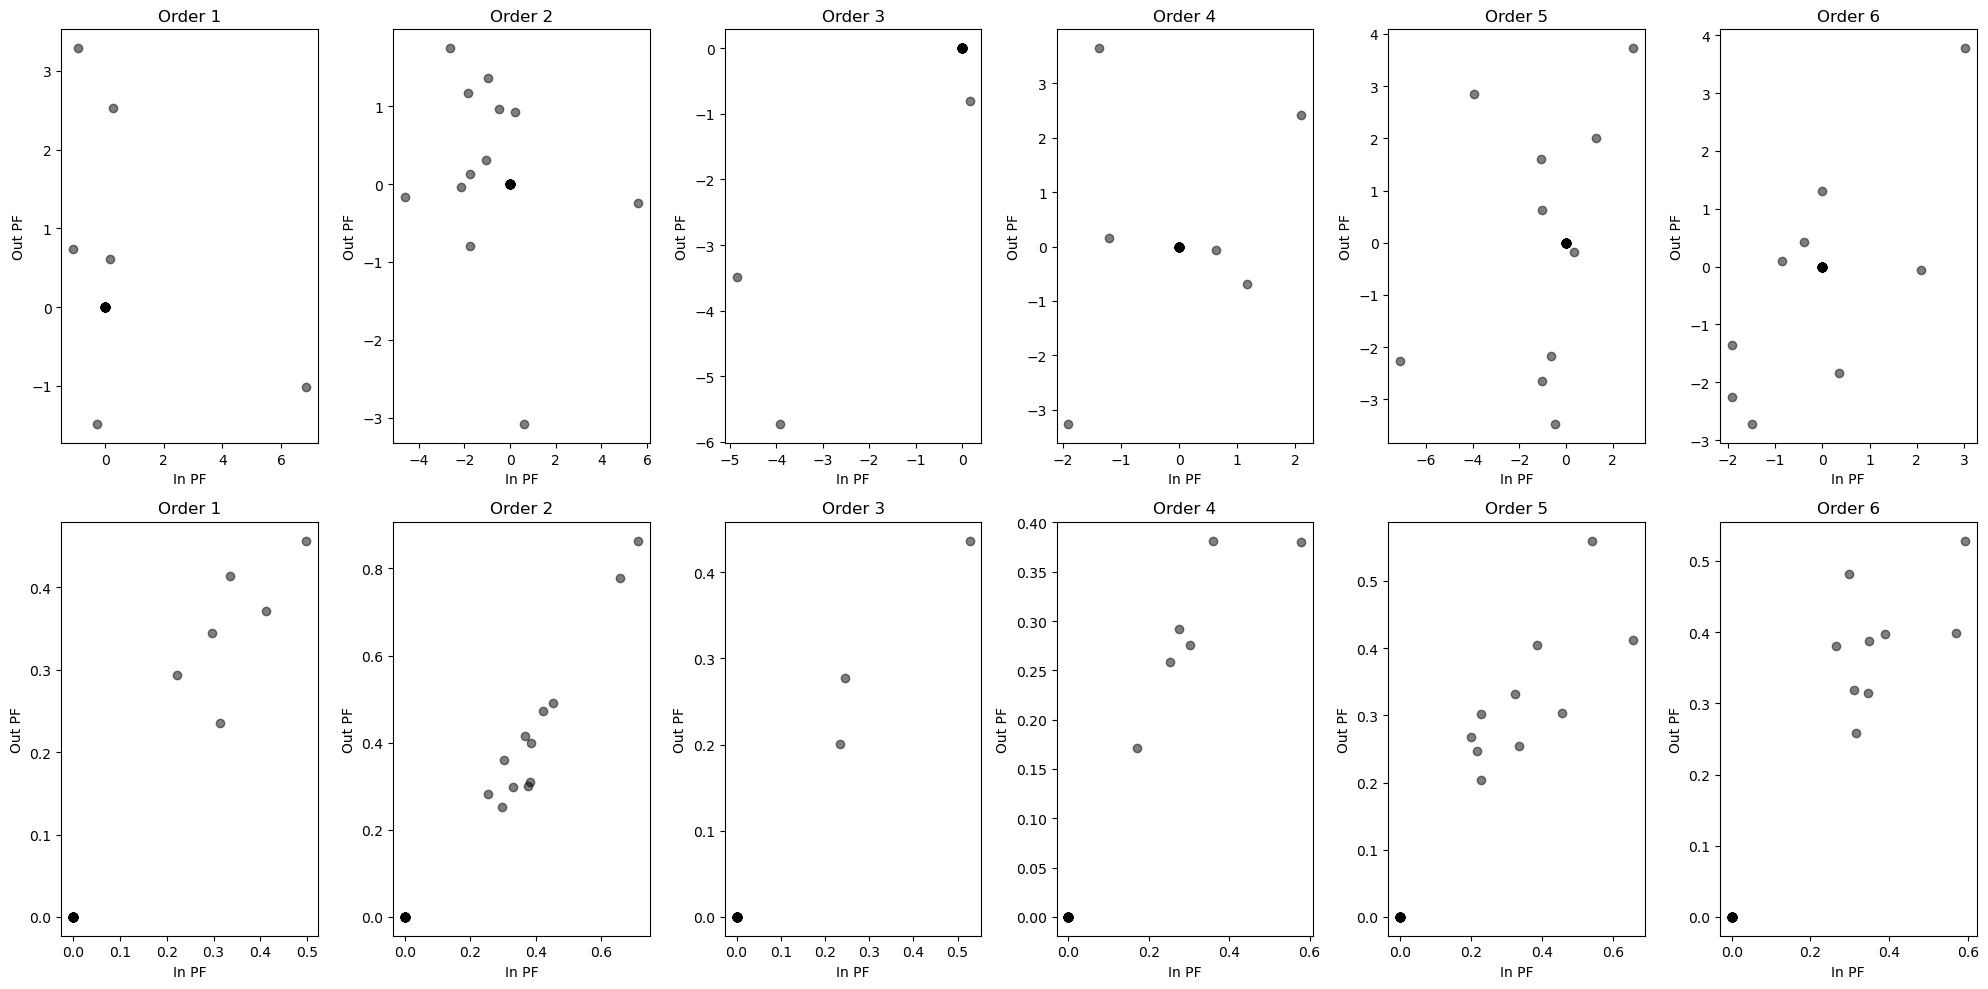

In [11]:
# Does order of manipulation impact task performance?
df_temp = df.copy()

# Metrics = (mean, std, var, skew, kurt); blockTypes = 123, 132, 213, 231, 312, 321; TMStypes = No TMS, Early TMS, Middle TMS; stimPF = 0, 1
summaryData = np.zeros((40, 5, 6, 3, 2))

counter = [0, 0, 0, 0, 0, 0]
for i, sidx in enumerate(df_temp['subjID'].unique()):
    for d in range(1,3):
        thDf = df_temp[(df_temp['subjID'] == sidx) & (df_temp['day'] == d)]
        thTMSCond = thDf['TMScond'].unique()
        # Check the order of manipulation
        if thTMSCond.tolist() == [1, 2, 3]:
            idx3 = 0
            counter[0] += 1
        elif thTMSCond.tolist() == [1, 3, 2]:
            idx3 = 1
            counter[1] += 1
        elif thTMSCond.tolist() == [2, 1, 3]:
            idx3 = 2
            counter[2] += 1
        elif thTMSCond.tolist() == [2, 3, 1]:
            idx3 = 3
            counter[3] += 1
        elif thTMSCond.tolist() == [3, 1, 2]:
            idx3 = 4
            counter[4] += 1
        elif thTMSCond.tolist() == [3, 2, 1]:
            idx3 = 5
            counter[5] += 1
        else:
            raise ValueError('Invalid order of manipulation')
        
        ntIn = thDf[(thDf['TMScond'] == 1) & (thDf['stimPF'] == 1)]
        earlyIn = thDf[(thDf['TMScond'] == 2) & (thDf['stimPF'] == 1)]
        middleIn = thDf[(thDf['TMScond'] == 3) & (thDf['stimPF'] == 1)]
        ntOut = thDf[(thDf['TMScond'] == 1) & (thDf['stimPF'] == 0)]
        earlyOut = thDf[(thDf['TMScond'] == 2) & (thDf['stimPF'] == 0)]
        middleOut = thDf[(thDf['TMScond'] == 3) & (thDf['stimPF'] == 0)]

        summaryData[counter[idx3]-1, :, idx3, 0, 0] = circ_stats(ntIn['errOri_scaled'])
        summaryData[counter[idx3]-1, :, idx3, 1, 0] = circ_stats(earlyIn['errOri_scaled'])
        summaryData[counter[idx3]-1, :, idx3, 2, 0] = circ_stats(middleIn['errOri_scaled'])
        summaryData[counter[idx3]-1, :, idx3, 0, 1] = circ_stats(ntOut['errOri_scaled'])
        summaryData[counter[idx3]-1, :, idx3, 1, 1] = circ_stats(earlyOut['errOri_scaled'])
        summaryData[counter[idx3]-1, :, idx3, 2, 1] = circ_stats(middleOut['errOri_scaled'])

# Plot number of sessions for each order of manipulation
plt.figure(figsize=(6, 4))
plt.bar(np.arange(1, 7), counter)
plt.xlabel('Order of manipulation')
plt.ylabel('Number of sessions')
plt.xticks(np.arange(1, 7), ['123', '132', '213', '231', '312', '321'])
plt.show()

# Scatter plot for inPF vs ouPF for each order of manipulation for mean error and precision
f, axs = plt.subplots(2, 6, figsize=(20, 10))
for i in range(6):
    for j in range(2):
        axs[j, i].scatter(summaryData[:, j, i, 0, 0], summaryData[:, j, i, 0, 1], color='black', alpha=0.5)
        axs[j, i].set_title(f'Order {i+1}')
        axs[j, i].set_xlabel('In PF')
        axs[j, i].set_ylabel('Out PF')
        # axs[j, i].plot([0, 0.2], [0, 0.2], 'k--')
        # axs[j, i].set_xlim(0, 0.2)
        # axs[j, i].set_ylim(0, 0.2)
    axs[0, i].set_title(f'Order {i+1}')
plt.tight_layout()
plt.show()

In [12]:
print(counter), print(sum(counter))

[6, 12, 3, 6, 10, 9]
46


(None, None)

In [ ]:
# Model-free: Population
summaryData = np.empty((len(df['subjID'].unique()), 5, 3))
orderStats = ['mean', 'std', 'var', 'skew', 'kurt']
metric_to_plot = 'errOri_scaled'
for i, sidx in enumerate(df['subjID'].unique()):
    sTemp = df[(df['subjID'] == sidx) & (df['stimPF'] == 1)]
    # sTemp = sTemp[sTemp['abserrorOri'] < 5 * sTemp['abserrorOri'].std()]
    sTemo = sTemp[(sTemp['initOffset'] > 25) | (sTemp['initOffset'] < -25)]
    
    nt_df = sTemp[sTemp['TMScond_label'] == 'No TMS']
    et_df = sTemp[sTemp['TMScond_label'] == 'Early TMS']
    mt_df = sTemp[sTemp['TMScond_label'] == 'Middle TMS']

    nt_mean, nt_std, nt_var, nt_skew, nt_kurt = circ_stats(nt_df[metric_to_plot])
    et_mean, et_std, et_var, et_skew, et_kurt = circ_stats(et_df[metric_to_plot])
    mt_mean, mt_std, mt_var, mt_skew, mt_kurt = circ_stats(mt_df[metric_to_plot])

    nt_mean = nt_df['abserrorOri'].mean()
    et_mean = et_df['abserrorOri'].mean()
    mt_mean = mt_df['abserrorOri'].mean()

    summaryData[i, :, :] = np.array([[nt_mean, nt_std, nt_var, nt_skew, nt_kurt], [et_mean, et_std, et_var, et_skew, et_kurt], [mt_mean, mt_std, mt_var, mt_skew, mt_kurt]]).T

f, axs = plt.subplots(2, 3, figsize=(15, 12))
axs = axs.flatten()
for i in range(5):
    sns.stripplot(data=summaryData[:, i, :], ax=axs[i], color='black', alpha=0.5, jitter=0.1)
    sns.barplot(data=summaryData[:, i, :], ax=axs[i], color=[0.8, 0, 0.8, 0.8], linewidth=1)
    axs[i].set_xticks([0, 1, 2])
    axs[i].set_xticklabels(['No TMS', 'Early TMS', 'Middle TMS'], rotation=45)
    axs[i].set_title(f'{orderStats[i]}')
plt.show()

# Perform repeated measures ANOVA for each metric
metrics = ['mean', 'std', 'var', 'skew', 'kurt']
results = {}

for i, metric in enumerate(metrics):
    # Reshape data: Each row corresponds to a subject's score in each condition
    data = pd.DataFrame({
        'subject': np.repeat(np.arange(len(df['subjID'].unique())), 3),
        'TMS_condition': np.tile(['No TMS', 'Early TMS', 'Middle TMS'], len(df['subjID'].unique())),
        'metric_value': summaryData[:, i, :].flatten()
    })

    # Perform repeated measures ANOVA
    anova_result = AnovaRM(data, 'metric_value', 'subject', within=['TMS_condition']).fit()
    results[metric] = anova_result

# Print ANOVA results
for metric, result in results.items():
    print(f"ANOVA results for {metric}:")
    print(result)
    print("\n")

# Conclusion:
# TMS has impact on precision of reported orientation but not on accuracy.
# Specifically, TMS reduces precision of memory and the impact is larger for early TMS compared to middle TMS

In [ ]:
nsubs = len(df['subjID'].unique())
orderStats = ['mean', 'std', 'var', 'skew', 'kurt']
nstats = len(orderStats)
ntms = df['TMScond_label'].nunique()
nori = df['targOriCategory'].nunique()
nloc = df['stimPF'].nunique()

summaryData = np.empty((nsubs, nstats, ntms, nori, nloc))
metric_to_plot = 'errOri_scaled'

for i, sidx in enumerate(df['subjID'].unique()):
    for j, ori in enumerate(df['targOriCategory'].unique()):
        for k, pf in enumerate(df['stimPF'].unique()):
            sTemp = df[(df['subjID'] == sidx) & (df['stimPF'] == pf) & (df['targOriCategory'] == ori)]
            sTemp = sTemp[sTemp['abserrorOri'] < 3 * sTemp['abserrorOri'].std()]
            # sTemo = sTemp[(sTemp['initOffset'] > 25) | (sTemp['initOffset'] < -25)]
            
            nt_df = sTemp[sTemp['TMScond_label'] == 'No TMS']
            et_df = sTemp[sTemp['TMScond_label'] == 'Early TMS']
            mt_df = sTemp[sTemp['TMScond_label'] == 'Middle TMS']

            nt_mean, nt_std, nt_var, nt_skew, nt_kurt = circ_stats(nt_df[metric_to_plot])
            et_mean, et_std, et_var, et_skew, et_kurt = circ_stats(et_df[metric_to_plot])
            mt_mean, mt_std, mt_var, mt_skew, mt_kurt = circ_stats(mt_df[metric_to_plot])

            nt_mean = nt_df['abserrorOri'].mean()
            et_mean = et_df['abserrorOri'].mean()
            mt_mean = mt_df['abserrorOri'].mean()

            summaryData[i, :, 0, j, k] = np.array([nt_mean, nt_std, nt_var, nt_skew, nt_kurt])
            summaryData[i, :, 1, j, k] = np.array([et_mean, et_std, et_var, et_skew, et_kurt])
            summaryData[i, :, 2, j, k] = np.array([mt_mean, mt_std, mt_var, mt_skew, mt_kurt])

data_for_anova = []

for subj_idx, subj_id in enumerate(df['subjID'].unique()):
    for stat_idx, stat in enumerate(orderStats):
        for tms_idx, tms_cond in enumerate(['No TMS', 'Early TMS', 'Middle TMS']):
            for ori_idx, ori_cat in enumerate(df['targOriCategory'].unique()):
                for stim_idx, stim_pf in enumerate(df['stimPF'].unique()):
                    data_for_anova.append({
                        'subjID': subj_id,
                        'TMScond_label': tms_cond,
                        'stimPF': stim_pf,
                        'targOriCategory': ori_cat,
                        'Statistic': stat,
                        'Value': summaryData[subj_idx, stat_idx, tms_idx, ori_idx, stim_idx]
                    })

from statsmodels.formula.api import ols
import statsmodels.api as sm
anova_df = pd.DataFrame(data_for_anova)
# anova_df.head(20)
# anova_df['TMScond_label'] = anova_df['TMScond_label'].astype('category')
# anova_df['targOriCategory'] = anova_df['targOriCategory'].astype('category')
# anova_df['stimPF'] = anova_df['stimPF'].astype('category')
# anova_df['subjID'] = anova_df['subjID'].astype('category')

# Run ANOVA for each statistic
results = {}
for stat in orderStats:
    anova_stat_df = anova_df[anova_df['Statistic'] == stat]
    model = ols('Value ~ C(targOriCategory) * C(TMScond_label) * C(stimPF) + C(subjID)', data=anova_stat_df).fit()
    aov_table = sm.stats.anova_lm(model, typ=2)
    results[stat] = aov_table
    print(f"ANOVA results for {stat}:")
    print(aov_table)
    print("\n" + "="*40 + "\n")

In [ ]:
# Visualize circular histogram of errors for each TMS condition
df_temp = df.copy()
# df_temp = df_temp[df_temp['abserrorOri'] < 3 * df_temp['abserrorOri'].std()]
f, axs = plt.subplots(1, 3, figsize=(15, 5))
for i, tms_cond in enumerate(['No TMS', 'Early TMS', 'Middle TMS']):
    thErr = df_temp[df_temp['TMScond_label'] == tms_cond]['errOri_scaled']
    
    sns.histplot(df_temp[df_temp['TMScond_label'] == tms_cond]['errOri_scaled'], bins=50, ax=axs[i], kde=True, color='blue',
                    stat='density')
    
    axs[i].set_title(tms_cond)
    axs[i].set_xlabel('Error')
    axs[i].set_ylabel('Density')
    axs[i].set_xlim([-90, 90])
    axs[i].set_ylim([0, 0.05])
plt.show()

In [ ]:
# Model-based: Individual
orderStats = ['mean', 'std', 'var', 'skew', 'kurt']
metric_to_plot = 'errOri_scaled'
ncols = 4
nrows = df['subjID'].nunique() // ncols + 1
f1, axs1 = plt.subplots(nrows, ncols, figsize=(15, 20))
axs1 = axs1.flatten()
f2, axs2 = plt.subplots(nrows, ncols, figsize=(15, 20))
axs2 = axs2.flatten()
for i, sidx in enumerate(df['subjID'].unique()):
    sTemp = df[(df['subjID'] == sidx) & (df['stimPF'] == 1)]
    sTemp = sTemp[sTemp['abserrorOri'] < 5 * sTemp['abserrorOri'].std()]
    # sTemo = sTemp[(sTemp['initOffset'] > 25) | (sTemp['initOffset'] < -25)]
    
    nt_df = sTemp[sTemp['TMScond_label'] == 'No TMS']
    et_df = sTemp[sTemp['TMScond_label'] == 'Early TMS']
    mt_df = sTemp[sTemp['TMScond_label'] == 'Middle TMS']

    nt_mean, nt_std, nt_var, nt_skew, nt_kurt = circ_stats(nt_df[metric_to_plot])
    et_mean, et_std, et_var, et_skew, et_kurt = circ_stats(et_df[metric_to_plot])
    mt_mean, mt_std, mt_var, mt_skew, mt_kurt = circ_stats(mt_df[metric_to_plot])

    nt_mean = nt_df['abserrorOri'].mean()
    et_mean = et_df['abserrorOri'].mean()
    mt_mean = mt_df['abserrorOri'].mean()
    nt_serr = nt_df['abserrorOri'].sem()
    et_serr = et_df['abserrorOri'].sem()
    mt_serr = mt_df['abserrorOri'].sem()

    axs1[i].bar(['No TMS', 'Early TMS', 'Middle TMS'], [nt_mean, et_mean, mt_mean], color=[0.8, 0, 0.8, 0.8], yerr=[nt_serr, et_serr, mt_serr], capsize=5)
    axs1[i].set_title(f'Subject {sidx}')
    axs1[i].set_ylabel('Mean')
    axs1[i].set_ylim([4, 11])

    axs2[i].bar(['No TMS', 'Early TMS', 'Middle TMS'], [nt_std, et_std, mt_std], color=[0.8, 0, 0.8, 0.8])
    axs2[i].set_title(f'Subject {sidx}')
    axs2[i].set_ylabel('Standard Deviation')
plt.show()

Optimization successful after 20 iterations, NLL = 18.814976618383806
Optimization successful after 21 iterations, NLL = 17.77675374207212
Optimization successful after 20 iterations, NLL = 13.770223318651052
Optimization successful after 20 iterations, NLL = 18.814976618376814
Optimization successful after 20 iterations, NLL = 17.776753742085944
Optimization successful after 20 iterations, NLL = 13.770223318648132
Optimization successful after 24 iterations, NLL = 18.79706200416063
Optimization successful after 20 iterations, NLL = 16.15205080381532
Optimization successful after 21 iterations, NLL = 11.518312353427643
Optimization successful after 23 iterations, NLL = 48.14836537487956
Optimization successful after 21 iterations, NLL = 61.72392109868261
Optimization successful after 21 iterations, NLL = 38.578437930735205
Optimization successful after 20 iterations, NLL = 43.029156146132856
Optimization successful after 20 iterations, NLL = 61.72392109866307
Optimization successful af

/System/Volumes/Data/d/DATD/hyper/experiments/Mrugank/TMS/srh_ori/oriAnalysis/analyzeBehav/modeller.py:147: RuntimeWarning: divide by zero encountered in log
  nll = -np.sum(np.log(pdf) + 1e-10) # Add a small number to avoid log(0)
/users/mrugank/.conda/envs/mgs/lib/python3.11/site-packages/scipy/optimize/_numdiff.py:576: RuntimeWarning: invalid value encountered in subtract
  df = fun(x) - f0


Optimization successful after 22 iterations, NLL = 51.11394041200228
Optimization successful after 21 iterations, NLL = 26.965198612902235
Optimization successful after 21 iterations, NLL = 38.34369689599902
Optimization successful after 20 iterations, NLL = 26.73282750374332
Optimization successful after 20 iterations, NLL = 26.965198612900814
Optimization successful after 20 iterations, NLL = 38.34369689600194
Optimization successful after 20 iterations, NLL = 26.73282750374321
Optimization successful after 24 iterations, NLL = 26.82731732291094
Optimization successful after 21 iterations, NLL = 38.343622419607215
Optimization successful after 21 iterations, NLL = 26.70910377341702
Optimization successful after 20 iterations, NLL = 37.356572441083415
Optimization successful after 23 iterations, NLL = 50.34843225521696
Optimization successful after 21 iterations, NLL = 87.08410997643429
Optimization successful after 20 iterations, NLL = 34.68352052529481
Optimization successful after 

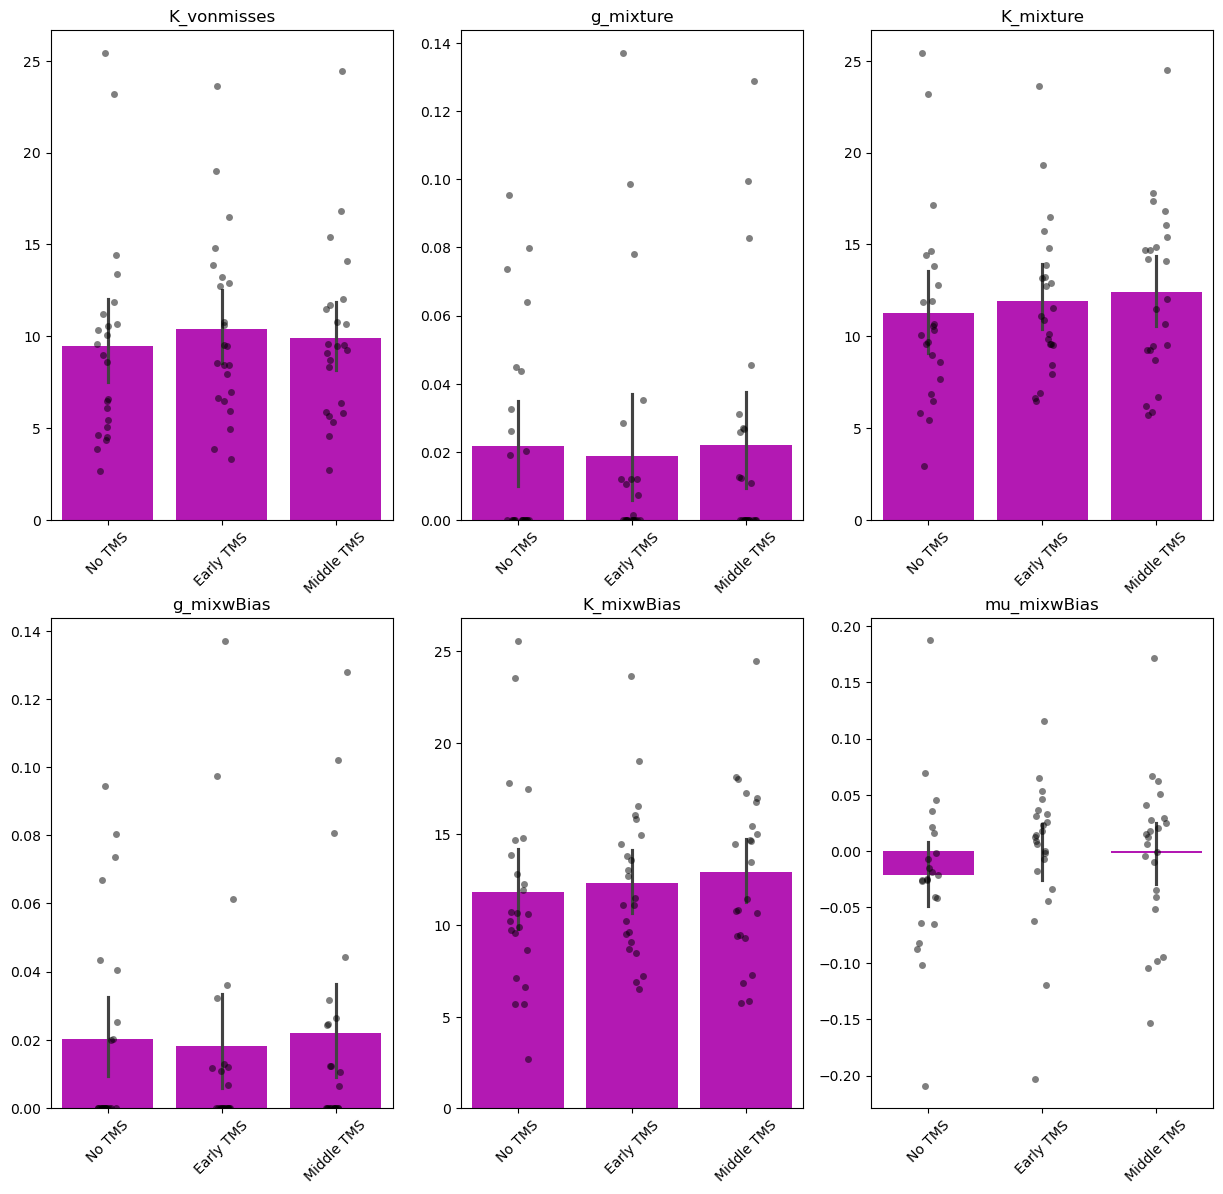

In [13]:
# Model-based: Population (Mixture model)
orderStats = ['K_vonmisses', 'g_mixture', 'K_mixture', 'g_mixwBias', 'K_mixwBias', 'mu_mixwBias']
summaryData = np.empty((len(df['subjID'].unique()), len(orderStats), 3))

metric_to_plot = 'errOri_scaled'
# df_temp['errOri_nobias'] = np.nan
# Fit a 4th order polynomial to the error data and remove the bias for each subject
for i, sidx in enumerate(df_temp['subjID'].unique()):
    subdf = df_temp[df_temp['subjID'] == sidx]
    
for i, sidx in enumerate(df['subjID'].unique()):
    sTemp = df[(df['subjID'] == sidx) & (df['stimPF'] == 1)]

    # Fit a 4th order polynomial to the error data
    # errorVals = sTemp['errOri_scaled'].values
    # x = sTemp['targOriActual'].values
    # y = errorVals
    # model = np.poly1d(np.polyfit(x, y, 4))
    # yfit = model(x)
    # sTemp.loc[sTemp['subjID'] == sidx, 'errOri_scaled'] = errorVals - yfit

    # sTemp = sTemp[sTemp['abserrorOri'] < 3 * sTemp['abserrorOri'].std()]
    # sTemp = sTemp[(sTemp['initOffset'] > 25) | (sTemp['initOffset'] < -25)]
    
    nt_df = sTemp[sTemp['TMScond_label'] == 'No TMS']
    et_df = sTemp[sTemp['TMScond_label'] == 'Early TMS']
    mt_df = sTemp[sTemp['TMScond_label'] == 'Middle TMS']

    # Fit von Mises model
    nt_vm_fit = fit_model(nt_df[metric_to_plot], 'vonMises')
    et_vm_fit = fit_model(et_df[metric_to_plot], 'vonMises')
    mt_vm_fit = fit_model(mt_df[metric_to_plot], 'vonMises')
    nt_k_vonmises, et_k_vonmises, mt_k_vonmises = nt_vm_fit[0], et_vm_fit[0], mt_vm_fit[0]

    # Fit mixture model
    nt_mix_fit = fit_model(nt_df[metric_to_plot], 'mixtureModel')
    et_mix_fit = fit_model(et_df[metric_to_plot], 'mixtureModel')
    mt_mix_fit = fit_model(mt_df[metric_to_plot], 'mixtureModel')
    nt_g_mixture, nt_K_mixture = nt_mix_fit[0], nt_mix_fit[1]
    et_g_mixture, et_K_mixture = et_mix_fit[0], et_mix_fit[1]
    mt_g_mixture, mt_K_mixture = mt_mix_fit[0], mt_mix_fit[1]

    # Fit mixture model with bias
    nt_mixwBias_fit = fit_model(nt_df[metric_to_plot], 'mixtureModelwithBias')
    et_mixwBias_fit = fit_model(et_df[metric_to_plot], 'mixtureModelwithBias')
    mt_mixwBias_fit = fit_model(mt_df[metric_to_plot], 'mixtureModelwithBias')
    nt_g_mixwBias, nt_K_mixwBias, nt_mu_mixwBias = nt_mixwBias_fit[0], nt_mixwBias_fit[1], nt_mixwBias_fit[2]
    et_g_mixwBias, et_K_mixwBias, et_mu_mixwBias = et_mixwBias_fit[0], et_mixwBias_fit[1], et_mixwBias_fit[2]
    mt_g_mixwBias, mt_K_mixwBias, mt_mu_mixwBias = mt_mixwBias_fit[0], mt_mixwBias_fit[1], mt_mixwBias_fit[2]

    # summaryData[i, :, :] = np.array([[nt_g, nt_K], [et_g, et_K], [mt_g, mt_K]]).T
    summaryData[i, :, :] = np.array([[nt_k_vonmises, nt_g_mixture, nt_K_mixture, nt_g_mixwBias, nt_K_mixwBias, nt_mu_mixwBias], 
                                     [et_k_vonmises, et_g_mixture, et_K_mixture, et_g_mixwBias, et_K_mixwBias, et_mu_mixwBias], 
                                     [mt_k_vonmises, mt_g_mixture, mt_K_mixture, mt_g_mixwBias, mt_K_mixwBias, mt_mu_mixwBias]]).T

ncols = 3
nrows = len(orderStats) // ncols 
f, axs = plt.subplots(nrows, ncols, figsize=(15, nrows*7))
axs = axs.flatten()
for i in range(len(orderStats)):
    sns.stripplot(data=summaryData[:, i, :], ax=axs[i], color='black', alpha=0.5, jitter=0.1)
    sns.barplot(data=summaryData[:, i, :], ax=axs[i], color=[0.8, 0, 0.8, 0.8], linewidth=1)# showfliers=False)
    axs[i].set_xticks([0, 1, 2])
    axs[i].set_xticklabels(['No TMS', 'Early TMS', 'Middle TMS'], rotation=45)
    axs[i].set_title(f'{orderStats[i]}')

# Perform repeated measures ANOVA for each metric
metrics = ['K_vonmisses', 'g_mixture', 'K_mixture', 'g_mixwBias', 'K_mixwBias', 'mu_mixwBias']
results = {}

for i, metric in enumerate(metrics):
    # Reshape data: Each row corresponds to a subject's score in each condition
    data = pd.DataFrame({
        'subject': np.repeat(np.arange(len(df['subjID'].unique())), 3),
        'TMS_condition': np.tile(['No TMS', 'Early TMS', 'Middle TMS'], len(df['subjID'].unique())),
        'metric_value': summaryData[:, i, :].flatten()
    })

    # Perform repeated measures ANOVA
    anova_result = AnovaRM(data, 'metric_value', 'subject', within=['TMS_condition']).fit()
    results[metric] = anova_result

# Print ANOVA results
for metric, result in results.items():
    print(f"ANOVA results for {metric}:")
    print(result)
    print("\n")

In [ ]:
plt.figure(figsize=(10, 5))
df_temp = df[df['stimPF'] == 1].copy()
sns.lmplot(x='initOffset', y='errOri_scaled', data=df_temp[df_temp['targOriCategory'] == 30], order=3, hue='TMScond_label', scatter_kws={'alpha': 0.1})
plt.ylim(-20, 20)
plt.show()

In [ ]:
grouped_df = df.groupby(['subjID', 'TMScond_label', 'stimPF_label']).agg({
    'RT': ['mean', 'sem'],
    'abserrorOri': ['mean', 'sem']
}).reset_index()

grouped_df.columns = ['subjID', 'TMScond', 'stimPF', 'RT_mean', 'RT_sem', 'abserrorOri_mean', 'abserrorOri_sem']

f, axs = plt.subplots(1, 2, figsize=(15, 5))

sns.pointplot(x='TMScond', y='RT_mean', data=grouped_df, ax=axs[0], hue='stimPF', dodge=0.4, 
              markers='o', capsize=.1, palette='dark', errorbar='se', order=['No TMS', 'Early TMS', 'Middle TMS'])

axs[0].set_title('TMScond vs RT')
axs[0].set_xlabel('TMScond')
axs[0].set_ylabel('RT')

sns.pointplot(x='TMScond', y='abserrorOri_mean', data=grouped_df, ax=axs[1], hue='stimPF', dodge=0.4, 
              markers='o', capsize=.1, palette='dark', errorbar='se', order=['No TMS', 'Early TMS', 'Middle TMS'])

axs[1].set_title('TMScond vs errorOri')
axs[1].set_xlabel('TMScond')
axs[1].set_ylabel('errorOri')

plt.show()

In [ ]:
f, axs = plt.subplots(df['subjID'].nunique(), 3, figsize=(15, 4*df['subjID'].nunique()), sharex=True, sharey=True)
meetric_to_plot = 'abserrorOri'
for idx, sub in enumerate(df['subjID'].unique()):
    subdf = df[df['subjID'] == sub]
    elimTrials = np.abs(subdf['abserrorOri'] - subdf['abserrorOri'].mean()) > 3*subdf['abserrorOri'].std()
    subdf = subdf[~elimTrials]
    # Find the number of trials for each TMS condition and stimulus position
    ntrls_noTMS_outPF = subdf[(subdf['TMScond']==1) & (subdf['stimPF']==0)].shape[0]
    ntrls_noTMS_inPF = subdf[(subdf['TMScond']==1) & (subdf['stimPF']==1)].shape[0]
    ntrls_earlyTMS_outPF = subdf[(subdf['TMScond']==2) & (subdf['stimPF']==0)].shape[0]
    ntrls_earlyTMS_inPF = subdf[(subdf['TMScond']==2) & (subdf['stimPF']==1)].shape[0]
    ntrls_middleTMS_outPF = subdf[(subdf['TMScond']==3) & (subdf['stimPF']==0)].shape[0]
    ntrls_middleTMS_inPF = subdf[(subdf['TMScond']==3) & (subdf['stimPF']==1)].shape[0]

    ntrls_min = min(ntrls_noTMS_outPF, ntrls_noTMS_inPF, ntrls_earlyTMS_outPF, ntrls_earlyTMS_inPF, ntrls_middleTMS_outPF, ntrls_middleTMS_inPF)
    subdf = subdf.groupby(['TMScond', 'stimPF']).apply(lambda x: x.sample(n=ntrls_min)).reset_index(drop=True)

    axs[idx, 0].plot(subdf[(subdf['TMScond']==1) & (subdf['stimPF']==0)][metric_to_plot], subdf[(subdf['TMScond']==1) & (subdf['stimPF']==1)][metric_to_plot], 'o', markersize=msize*0.3)
    axs[idx, 0].plot([0, 30], [0, 30], 'k--')
    axs[idx, 0].set_title(f'Subject {sub}, No TMS')
    axs[idx, 0].set_xlabel('Out PF')
    axs[idx, 0].set_ylabel('In PF')
    axs[idx, 0].set_aspect('equal')

    axs[idx, 1].plot(subdf[(subdf['TMScond']==2) & (subdf['stimPF']==0)][metric_to_plot], subdf[(subdf['TMScond']==2) & (subdf['stimPF']==1)][metric_to_plot], 'o', markersize=msize*0.3)
    axs[idx, 1].plot([0, 30], [0, 30], 'k--')
    axs[idx, 1].set_title(f'Subject {sub}, Early TMS')
    axs[idx, 1].set_xlabel('Out PF')
    axs[idx, 1].set_ylabel('In PF')
    axs[idx, 1].set_aspect('equal')

    axs[idx, 2].plot(subdf[(subdf['TMScond']==3) & (subdf['stimPF']==0)][metric_to_plot], subdf[(subdf['TMScond']==3) & (subdf['stimPF']==1)][metric_to_plot], 'o', markersize=msize*0.3)
    axs[idx, 2].plot([0, 30], [0, 30], 'k--')
    axs[idx, 2].set_title(f'Subject {sub}, Middle TMS')
    axs[idx, 2].set_xlabel('Out PF')
    axs[idx, 2].set_ylabel('In PF')
    axs[idx, 2].set_aspect('equal')
plt.show()
    